### Setup: CART Repository and Dataset Access



This section installs Git LFS, clones the CART repository, and downloads the datasets required for narrative clustering. All data are loaded directly from GitHub.

In [1]:
import os

# Install Git LFS
!apt-get update -qq
!apt-get install -y -qq git-lfs
!git lfs install

# Clone the CART repository
repo_path = "/content/cart"

if not os.path.exists(os.path.join(repo_path, ".git")):
    !git clone https://github.com/semoglou/cart.git {repo_path}

%cd /content/cart

# Download the narrative embeddings from Git LFS
!git lfs pull --include="dataset/3_narrative_taxonomy/narrative_embeddings.npy" --exclude=""

# Verify that the embeddings are available
embeddings_path = os.path.join(
    repo_path,
    "dataset/3_narrative_taxonomy/narrative_embeddings.npy"
)

assert os.path.isfile(embeddings_path), "Narrative embeddings file not found."
assert os.path.getsize(embeddings_path) > 1024 * 1024, "Narrative embeddings were not downloaded correctly."

print("CART repository and narrative embeddings are ready.")
print(f"Embeddings size: {os.path.getsize(embeddings_path) / 1024**2:.1f} MB")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package git-lfs.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...
Git LFS initialized.
Cloning into '/content/cart'...
remote: Enumerating objects: 144, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 144 (delta 15), reused 13 (delta 13), pack-reused 125 (from 4)
Receiving objects: 100% (144/144), 240.52 MiB | 23.38 MiB/s, done.
Resolving deltas: 100% (40/40), done.
Filtering content: 100% (2/2), 1.86 GiB | 6.25 MiB/s, done.
/content/cart
CART repository and narrative embeddings are read

### Methods

#### **K-Sil Clustering Algorithm**
We use K-Sil (https://arxiv.org/abs/2506.12878) for narrative clustering.

In [2]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import euclidean_distances
from joblib import Parallel, delayed

class KSil:
    def __init__(self,
                 n_clusters=3,
                 init='random',
                 max_iter=100,
                 random_state=0,
                 init_temperature=1.0,
                 learning_rate=0.2,
                 tol=1e-4,
                 n_init=1, n_jobs=1):

        # Parameters
        self.n_clusters = int(n_clusters)     # Number of clusters
        self.init = init                      # Initialization method
        self.max_iter = int(max_iter)         # Maximum number of iterations
        self.init_temperature = float(init_temperature) # Initial temperature
        self.random_state = int(random_state) # Random seed
        self.learning_rate = learning_rate    # Learning rate for temperature
        self.tol = float(tol)                 # Centroid convergence tolerance

        # For multiple initializations:
        self.n_init = n_init                  # Number of initializations
        self.n_jobs = n_jobs                  # Number of cores

        # n_clusters check
        if self.n_clusters < 2:
           raise ValueError(f"n_clusters ({self.n_clusters}) must be > 1.")
        # init check
        if isinstance(self.init, str) and self.init not in ('random', 'k-means++'):
           raise ValueError(f"init ({self.init}) must be 'random' or 'k-means++'.")
        # n_init check
        if self.n_init < 1:
           raise ValueError(f"n_init ({self.n_init}) must be > 0.")

        # Attributes
        self.labels_ = None          # Cluster labels (converged partition)
        self.cluster_centers_ = None # Cluster centers (converged partition)
        self.n_iter_ = None          # Number of iterations (until convergence)
        self.sil_ = None             # silhouette (centroid-approximated) at converged partition

        # history attributes
        self.centers_history_ = None # Centroids across iterations
        self.labels_history_ = None  # Assignments across iterations
        self.sil_history_ = None     # Silhouette proxy across iterations
        self.weights_history_ = None # Weights across iterations

    def _initialization(self, X, n_clusters):
        X = np.asarray(X)
        if X.shape[0] < n_clusters:
           raise ValueError(f"n_clusters ({n_clusters}) can not exceed n_samples ({X.shape[0]}).")

        kmeans = KMeans(n_clusters=n_clusters,
                        init=self.init,
                        random_state=self.random_state,
                        n_init=1,
                        max_iter=1).fit(X)
        centers = kmeans.cluster_centers_
        labels = kmeans.labels_

        # Retry if some clusters are empty in the initial assignment
        if np.unique(labels).size < n_clusters:
           max_retries = 10 # 10 retries at max
           base_seed = self.random_state
           for attempt in range(1, max_retries + 1):
               seed = base_seed + attempt
               km = KMeans(n_clusters=n_clusters,
                           init=self.init,
                           random_state=seed,
                           n_init=1,
                           max_iter=1).fit(X)
               centers = km.cluster_centers_
               labels = km.labels_
               if np.unique(labels).size == n_clusters:
                  break
           else:
               raise ValueError(
                     f"KMeans (1-iter) initialization produced empty clusters after {max_retries} retries. "
                     f"Try a different random_state, or init='k-means++'.")
        return centers, labels

    def _fit_once(self, X, n_clusters, previous_centers, w):
        X = np.asarray(X)
        w = np.asarray(w)
        km = KMeans(
             n_clusters=n_clusters,
             init=previous_centers,
             n_init=1,
             max_iter=1,
             random_state=self.random_state)
        km.fit(X, sample_weight=w)

        centers = km.cluster_centers_
        labels = km.labels_
        return centers, labels

    @staticmethod
    def sil_scores(X, labels, centers):
        X = np.asarray(X, dtype=float)
        labels = np.asarray(labels, dtype=int)
        centers = np.asarray(centers, dtype=float)

        if len(X) == 0:
           raise ValueError("X is empty. Cannot compute silhouette scores.")

        n = X.shape[0]

        # Squared distances to all centroids
        D = euclidean_distances(X, centers, squared=True)

        # Distance to own centroid (a: intra cluster distance proxy)
        D_diag = D[np.arange(n), labels]  # a^2
        a_vals = np.sqrt(D_diag)  # a

        # Nearest other centroid distance (b: inter cluster distance)
        D_others = D.copy()
        D_others[np.arange(n), labels] = np.inf
        b_sq = D_others.min(axis=1)  # b^2
        b_vals = np.sqrt(b_sq)  # b

        # Silhouette surrogate (b-a)/[max{a,b}+epsilon]
        max_ab = np.maximum(np.maximum(a_vals, b_vals), 1e-12)
        s_vals = (b_vals - a_vals) / max_ab

        return s_vals, a_vals, b_vals

    @staticmethod
    def micro_sil(s_vals):
        s_vals = np.asarray(s_vals, dtype=float)
        if s_vals.size == 0:
           return 0.0
        return float(s_vals.mean())

    @staticmethod
    def macro_sil(s_vals, labels):
        s_vals = np.asarray(s_vals, dtype=float)
        labels = np.asarray(labels, dtype=int)

        if s_vals.size == 0 or labels.size == 0:
           return 0.0

        uniq, inv = np.unique(labels, return_inverse=True)
        if uniq.size == 0:
           return 0.0
        sum_per_cluster = np.bincount(inv, weights=s_vals)
        cnt_per_cluster = np.bincount(inv)

        valid = cnt_per_cluster > 0
        if not np.any(valid):
           return 0.0
        cluster_means = sum_per_cluster[valid] / cnt_per_cluster[valid]
        return float(cluster_means.mean())

    def _weights(self, s_vals, temperature):
        s_vals = np.asarray(s_vals, dtype=float)
        weights = np.exp(s_vals * temperature)
        return weights

    def _KSil(self, X, n_clusters, max_iter):

        # Initialize centroids
        centers, labels = self._initialization(X, n_clusters)
        tau = self.init_temperature # initial temperature
        prev_score =  None

        centers_history = [centers.copy()]
        labels_history = [labels.copy()]
        sil_history = []
        weights_history = []

        n_iter = 0

        while n_iter < max_iter:

            n_iter += 1

            # Compute point-silhouette scores
            sil_vals, a_vals, b_vals = KSil.sil_scores(X, labels, centers)
            score = KSil.macro_sil(sil_vals, labels)

            micro_sil = KSil.micro_sil(sil_vals)
            sil_history.append(micro_sil)

            # Update temperature
            if prev_score is not None:
               r = (score - prev_score) / max(1 - prev_score, 1e-12)

               r = float(np.clip(r, -1.0, 1.0))

               # data-driven bounds to avoid softmax saturation
               counts = np.bincount(labels, minlength=n_clusters)
               m_max = int(max(counts.max(), 2))
               L     = float(np.sqrt(2.0 * np.log(m_max)))
               z_max = (m_max - 1) / m_max
               tau_min, tau_max = 1e-12, L / max(z_max, 1e-8)

               # multiplicative update (no logs needed)
               eta = self.learning_rate # default: 0.2 (small stable learning rate)

               # Update temperature based on the rate of change of the silhouette objective
               tau = float(np.clip(tau * np.exp(eta * r), tau_min, tau_max))

            # store for next iteration’s drift calc
            prev_score = score

            # Retain previous centroids for convergence checking
            previous_centers = centers.copy()

            # Compute weights based on silhouette scores
            weights = self._weights(sil_vals, tau)

            weights_history.append(weights.copy())

            # Update centroids and assignments
            centers, labels = self._fit_once(X, n_clusters, previous_centers, weights)

            centers_history.append(centers.copy())
            labels_history.append(labels.copy())

            avg_move = np.linalg.norm(centers - previous_centers, axis=1).mean()

            # Centroid stability
            if avg_move < self.tol:
               break

        return centers, labels, n_iter, sil_history, centers_history, labels_history, weights_history

    def fit(self, X):
        """
        Run KSil on X and store the converged partition.
        X: array-like, shape (n_samples, n_features)
        """
        X_arr = X.values if hasattr(X, "values") else np.asarray(X, dtype=float)

        if self.n_init == 1:
           (centers,
           labels,
           n_iter,
           sil_history,
           centers_history,
           labels_history,
           weights_history) = self._KSil(X_arr, self.n_clusters, self.max_iter)
        else:
           base_seed = self.random_state
           seeds = [int(base_seed) + i for i in range(self.n_init)]

           # Helper: directly call _KSil with a seed
           def _run_one(seed):
               self.random_state = seed
               return self._KSil(X_arr, self.n_clusters, self.max_iter)

           if self.n_jobs in (None, 1):
              results = [_run_one(seed) for seed in seeds]
           else:
              results = Parallel(n_jobs=self.n_jobs)(delayed(_run_one)(seed) for seed in seeds)

           # Pick best run by final silhouette
           best_idx = None
           best_sil = -np.inf

           for i, res in enumerate(results):
               (_, _, _, sil_history_i,
               _, _, _) = res
               if sil_history_i:
                  final_sil_i = sil_history_i[-1]
               else:
                  final_sil_i = -np.inf
               if final_sil_i > best_sil:
                   best_sil = final_sil_i
                   best_idx = i

           (centers,
           labels,
           n_iter,
           sil_history,
           centers_history,
           labels_history,
           weights_history) = results[best_idx]

           self.random_state = base_seed # restore base random_state

        self.cluster_centers_ = centers
        self.labels_ = labels
        self.n_iter_ = n_iter

        self.sil_history_ = sil_history
        self.sil_ = sil_history[-1] if sil_history else None
        self.centers_history_ = centers_history
        self.labels_history_ = labels_history
        self.weights_history_ = weights_history

        return self

    def predict(self, X):
        """
        Assign new points to the nearest learned centroid.
        """
        if self.cluster_centers_ is None:
           raise ValueError("KSil model is not fitted yet. Call '.fit(...)' first.")

        X_arr = X.values if hasattr(X, "values") else np.asarray(X, dtype=float)
        dist_matrix = euclidean_distances(X_arr, self.cluster_centers_, squared=True)
        labels = np.argmin(dist_matrix, axis=1)
        return labels.astype(int)

    def transform(self, X):
        """
        Return distances of each sample to each centroid.
        """
        if self.cluster_centers_ is None:
           raise ValueError("KSil model is not fitted yet. Call '.fit(...)' first.")

        X_arr = X.values if hasattr(X, "values") else np.asarray(X, dtype=float)
        distances = euclidean_distances(X_arr, self.cluster_centers_, squared=False)
        return distances

    def fit_predict(self, X):
        """
        Equivalent to: fit(X); return labels_.
        """
        self.fit(X)
        return self.labels_

    def fit_transform(self, X):
        """
        Equivalent to: fit(X); return transform(X).
        """
        self.fit(X)
        return self.transform(X)

#### **Composite Silhouette**
We use Composite Silhouette for selecting the number of clusters.

In [3]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.utils import resample
import matplotlib.pyplot as plt
from joblib import Parallel, delayed


class CompSil:
    """
    Composite Silhouette (CompSil)

    Per subsample b=1..B for each k:
      - compute S_micro^(b), S_macro^(b)
      - Δ_b = S_micro^(b) - S_macro^(b)
      - D = max_b |Δ_b|
      - r_raw_b = Δ_b/(D+eps) in [-1,1]
      - r_b = tanh(r_raw_b)
      - w_b = (1+r_b)/2
      - S_mM^(b) = w_b*S_micro^(b) + (1-w_b)*S_macro^(b)

    Aggregate for each k:
      - mean score:   S_mM(k)  = mean_b S_mM^(b)
      - std score:    std_S_mM(k) = std_b  S_mM^(b)
      - standard error: se_S_mM(k) = std_S_mM(k) / sqrt(B_eff)
      - lower conf bound: LCB_S_mM(k) = S_mM(k) - se_S_mM(k)

    Selection:
      - k* = argmax_k S_mM(k) (or argmax_k LCB_S_mM(k))

    Sampling size mechanism:
      - explicit `sample_size` (int), or
      - sample_size=None or sample_size="auto", the class chooses a subsample size automatically
        based on dataset size N and the maximum k in `k_values`.

    Parameters:
    - data: ndarray or DataFrame, shape (n_samples, n_features)
    - ground_truth: int, optional
    - k_values: iterable or int, default=range(2, 11)
    - num_samples: int, default=100  (B)
    - sample_size: int | float | None | "auto", default=1000
        * int: absolute subsample size m
        * float in (0,1]: treated as fraction f, m = floor(f*N)
        * None or "auto": compute m automatically (see _auto_sample_size)
    - random_state: int, default=42
    - n_jobs: int, default=-1
    - eps: float, default=1e-12
    """

    def __init__(self,
                 data,
                 ground_truth=None,
                 k_values=range(2, 11),
                 num_samples=10,
                 sample_size="auto",
                 random_state=42,
                 n_jobs=-1,
                 eps=1e-12):
        self.data = data
        self.ground_truth = ground_truth
        self.k_values = [k_values] if isinstance(k_values, int) else list(k_values)
        self.num_samples = int(num_samples)
        self.random_state = int(random_state)
        self.n_jobs = int(n_jobs)
        self.eps = float(eps)

        self._results = []
        self.results_df = pd.DataFrame()
        self.score_ = None  # set only if one k is evaluated

        self.n_samples_ = int(len(self.data))
        if self.n_samples_ <= 0:
            raise ValueError("Empty dataset.")

        self.sample_size = self._resolve_sample_size(sample_size)
        self.sample_fraction_ = self.sample_size / self.n_samples_

        if self.sample_size < 2:
            raise ValueError(f"Resolved sample_size={self.sample_size} is too small.")
        if self.sample_size > self.n_samples_:
            raise ValueError(
                f"Resolved sample_size={self.sample_size} is larger than n_samples={self.n_samples_}."
            )

    def _resolve_sample_size(self, sample_size):
        n = self.n_samples_

        # Auto
        if sample_size is None or (isinstance(sample_size, str) and sample_size.lower() == "auto"):
            return self._auto_sample_size()

        # Fraction mode (float in (0,1])
        if isinstance(sample_size, float):
            if not (0.0 < sample_size <= 1.0):
                raise ValueError("If sample_size is a float, it must be in (0, 1].")
            m = int(np.floor(sample_size * n))
            return max(2, min(m, n))

        # Int mode
        m = int(sample_size)
        return m

    def _auto_sample_size(self):
        """
        Automatic subsample size selection (no user-facing hyperparameters).

        Heuristic:
          1) Ensure a minimum average points-per-cluster at k_max: m >= 30 * k_max
          2) Use a baseline fraction depending on dataset size:
             - small N: 0.8N
             - medium N: 0.6N
             - large N: 0.4N
          3) Take the maximum of (1) and (2), then cap at N.
        """
        n = self.n_samples_
        k_max = int(max(self.k_values)) if len(self.k_values) > 0 else 2

        m_min = 30 * k_max

        if n <= 2000:
            m_base = int(np.floor(0.80 * n))
        elif n <= 20000:
            m_base = int(np.floor(0.60 * n))
        else:
            m_base = int(np.floor(0.40 * n))

        m = max(m_min, m_base)
        m = min(max(2, m), n)
        return m

    def evaluate_sample(self, k, i):
        """
        One subsampling iteration for fixed k.
        Returns: (smicro, smacro, diff, s_mm_b)
        """
        seed = self.random_state + i

        sampled_data = resample(
            self.data,
            n_samples=self.sample_size,
            replace=False,
            random_state=seed
        )

        kmeans = KMeans(n_clusters=k, random_state=seed, n_init=1)
        labels = kmeans.fit_predict(sampled_data)

        try:
            s = silhouette_samples(sampled_data, labels)  # compute once

            # micro silhouette
            smicro = float(np.mean(s))

            labs = np.asarray(labels)
            uniq = np.unique(labs)
            cluster_means = [float(np.mean(s[labs == u])) for u in uniq]

            # macro silhouette
            smacro = float(np.mean(cluster_means)) if len(cluster_means) > 0 else np.nan
        except Exception:
            return np.nan, np.nan, np.nan, np.nan

        diff = smicro - smacro
        return smicro, smacro, diff, np.nan

    @staticmethod
    def _tanh_rb_weights_from_differences(differences, eps=1e-12):
        """
        Given Δ_b over b=1..B, compute:
          D       = max |Δ_b|
          r_raw_b = Δ_b/(D+eps) in [-1, 1]
          r_b     = tanh(r_raw_b)
          w_b     = (1+r_b)/2 in (0,1)
        """
        d = np.asarray(differences, dtype=float)
        finite = np.isfinite(d)

        if not np.any(finite):
            return d * np.nan, d * np.nan, np.nan

        D = float(np.max(np.abs(d[finite])))
        denom = D + float(eps)

        if D == 0.0:
            r = np.zeros_like(d)
            r[~finite] = np.nan
            w = 0.5 * np.ones_like(d)
            w[~finite] = np.nan
            return w, r, D

        r_raw = d / denom
        r_raw = np.clip(r_raw, -1.0, 1.0)
        r_raw[~finite] = np.nan

        r = np.tanh(r_raw)
        r[~finite] = np.nan

        w = 0.5 * (1.0 + r)
        w[~finite] = np.nan

        return w, r, D

    def evaluate(self):
        """
        Evaluate over k_values using subsampled clustering.
        Stores results in self.results_df.

        Output columns (per k):
        - avg S_micro
        - avg S_macro
        - w_micro (mean of per-subsample weights; descriptive)
        - S_mM (mean of per-subsample composites)
        - std S_mM
        - se S_mM
        - LCB S_mM  (S_mM - se)
        """
        self._results = []

        for k in self.k_values:
            results = Parallel(n_jobs=self.n_jobs)(
                delayed(self.evaluate_sample)(k, i) for i in range(self.num_samples)
            )

            smicro_list, smacro_list, differences, _ = zip(*results)

            smicro_arr = np.asarray(smicro_list, dtype=float)
            smacro_arr = np.asarray(smacro_list, dtype=float)
            diff_arr = np.asarray(differences, dtype=float)

            avg_smicro = float(np.nanmean(smicro_arr)) if np.any(np.isfinite(smicro_arr)) else np.nan
            avg_smacro = float(np.nanmean(smacro_arr)) if np.any(np.isfinite(smacro_arr)) else np.nan

            # weights
            w_b, r_b, D = self._tanh_rb_weights_from_differences(diff_arr, eps=self.eps)

            # per-subsample composite
            S_b = w_b * smicro_arr + (1.0 - w_b) * smacro_arr

            # mean composite
            S_mM = float(np.nanmean(S_b)) if np.any(np.isfinite(S_b)) else np.nan

            # descriptive mean weight
            w_micro_mean = float(np.nanmean(w_b)) if np.any(np.isfinite(w_b)) else np.nan

            # LCB components computed from S_b across valid subsamples
            finite_sb = np.isfinite(S_b)
            B_eff = int(np.sum(finite_sb))
            if B_eff >= 2:
                std_smm = float(np.nanstd(S_b, ddof=1))
                se_smm = std_smm / np.sqrt(B_eff)
            elif B_eff == 1:
                std_smm = 0.0
                se_smm = 0.0
            else:
                std_smm = np.nan
                se_smm = np.nan

            lcb_smm = (S_mM - se_smm) if (np.isfinite(S_mM) and np.isfinite(se_smm)) else np.nan

            if len(self.k_values) == 1:
                self.score_ = S_mM

            result = {
                'k': int(k),
                'avg S_micro': avg_smicro,
                'avg S_macro': avg_smacro,
                'w_micro': w_micro_mean,
                'S_mM': S_mM,
                'std S_mM': std_smm,
                'se S_mM': se_smm,
                'LCB S_mM': lcb_smm,
                'B_eff': B_eff,
                'sample_size': int(self.sample_size),
                'sample_fraction': float(self.sample_fraction_),
            }
            self._results.append(result)

        self.results_df = pd.DataFrame(self._results)

    def plot_results(self):
        """
        Plot S_mM and individual averages vs k.
        """
        if self.results_df.empty:
            raise ValueError("No results available. Run evaluate() first.")
        if len(self.results_df) == 1:
            raise ValueError("Cannot plot with only one k. Evaluate multiple k values.")

        max_smicro = self.results_df['avg S_micro'].max()
        max_smicro_k = self.results_df.loc[self.results_df['avg S_micro'].idxmax(), 'k']

        max_smacro = self.results_df['avg S_macro'].max()
        max_smacro_k = self.results_df.loc[self.results_df['avg S_macro'].idxmax(), 'k']

        max_smm = self.results_df['S_mM'].max()
        max_smm_k = self.results_df.loc[self.results_df['S_mM'].idxmax(), 'k']

        plt.figure(figsize=(10, 4))

        if self.ground_truth is not None:
            plt.axvline(
                x=self.ground_truth, color='red', linestyle='--', linewidth=2.5,
                label='Ground Truth'
            )

        plt.plot(
            self.results_df['k'], self.results_df['avg S_micro'],
            marker='o', linestyle='-', color='orange', linewidth=4, markersize=8, label='avg S_micro'
        )
        plt.plot(max_smicro_k, max_smicro, marker='*', color='orange', markersize=18)

        plt.plot(
            self.results_df['k'], self.results_df['avg S_macro'],
            marker='o', linestyle='-', color='blue', linewidth=4, markersize=8, label='avg S_macro'
        )
        plt.plot(max_smacro_k, max_smacro, marker='*', color='blue', markersize=18)

        plt.plot(
            self.results_df['k'], self.results_df['S_mM'],
            marker='o', linestyle='--', color='green', linewidth=4, markersize=8, label='S_mM'
        )
        plt.plot(max_smm_k, max_smm, marker='*', color='green', markersize=18)

        plt.xlabel('k', fontsize=15)
        plt.xticks(self.k_values, fontsize=14)
        plt.yticks(fontsize=14)
        plt.tick_params(axis='y', which='both', length=0)
        plt.grid(axis='y', linestyle='--')

        ax = plt.gca()
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.spines['top'].set_visible(False)

        handles, labels = ax.get_legend_handles_labels()
        ax.legend(
            handles, labels,
            loc="lower left",
            bbox_to_anchor=(0, 1.02, 1, 0.2),
            mode="expand",
            ncol=len(labels),
            frameon=False,
            fontsize=12
        )

        plt.tight_layout()
        plt.show()

    def get_optimal_k(self, use_lcb=False):
        """
        Return optimal k.

        By default, uses max selection:
          k* = argmax_k (S_mM) (use_lcb for argmax_k (LCB S_mM) selection)

        """
        if self.results_df.empty:
            raise ValueError("No results available. Run evaluate() first.")

        if len(self.results_df) == 1:
            return int(self.results_df['k'].iloc[0])

        col = 'LCB S_mM' if use_lcb else 'S_mM'
        if col not in self.results_df.columns:
            raise ValueError(f"Missing column '{col}'. Run evaluate() first.")

        optimal_row = self.results_df.loc[self.results_df[col].idxmax()]
        return int(optimal_row['k'])

    def get_results_dataframe(self):
        """
        Return results DataFrame indexed by k.
        """
        if self.results_df.empty:
            raise ValueError("No results available. Run evaluate() first.")
        return self.results_df.set_index('k', inplace=False)

#### **CAKE**
We have used CAKE (https://arxiv.org/abs/2602.18435) previously for confidence estimation when clustering the proceedings paragraphs. Currently we use some methods of the class for fast (approximate) Silhouette computation.

In [4]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.metrics import silhouette_samples, confusion_matrix
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import LabelEncoder

def sil_samples(X, labels, approximation=False, centers=None):
    """
    Compute silhouette scores for each point in the dataset,
    with approximate fast centroid-based computation option.
    """
    # Ensure arrays
    X = np.asarray(X)
    labels = np.asarray(labels)
    if X.ndim != 2:
       raise ValueError("X must be a 2D array of shape (n_samples, n_features).")
    if labels.ndim != 1 or labels.shape[0] != X.shape[0]:
       raise ValueError("labels must be a 1D array of length n_samples.")

    unique_labels, inv = np.unique(labels, return_inverse=True)
    k = unique_labels.size
    if k < 2:
       raise ValueError("Silhouette computation requires at least 2 clusters.")

    # Exact silhouette scores
    if approximation == False:
       silhouette_scores = silhouette_samples(X, labels=labels)
       return silhouette_scores

    # Centroid-based approximate silhouette scores
    n_samples, n_features = X.shape

    if centers is None:
       centers = np.array([X[inv == i].mean(axis=0) for i in range(k)], dtype=float)
    else:
       centers = np.asarray(centers, dtype=float)
       if centers.ndim != 2 or centers.shape[1] != n_features:
          raise ValueError(f"centers must have shape (k, d) with d={n_features}.")
       if centers.shape[0] != k:
          raise ValueError(f"centers.shape[0] must equal number of clusters k={k}.")
       if not np.array_equal(unique_labels, np.arange(k)):
          raise ValueError("When passing ndarray centers, labels must be dense 0..k-1.")

    # Squared distances to all centroids
    D_sq = euclidean_distances(X, centers, squared=True)

    # a(i): distance to own centroid
    a = np.sqrt(np.maximum(D_sq[np.arange(n_samples), inv], 0.0))

    # b(i): distance to nearest other centroid
    D_sq[np.arange(n_samples), inv] = np.inf
    b = np.sqrt(np.min(D_sq, axis=1))

    # Silhouette per point
    denom = np.maximum(np.maximum(a, b), 1e-12)
    s_point = (b - a) / denom

    # Singleton clusters -> silhouette = 0
    counts = np.bincount(inv, minlength=k).astype(int)
    s_point[counts[inv] < 2] = 0.0

    silhouette_scores = np.clip(s_point, -1.0, 1.0)

    return silhouette_scores

def sil_samples_stats(X, labels_list, approximation=False, centers_list=None):
    """
    Compute and aggregate silhouette scores across multiple clustering runs,
    returning per-sample mean and standard deviation of silhouette scores.
    """
    X = np.asarray(X)
    n_samples = X.shape[0]
    n_runs = len(labels_list)
    if n_runs < 2:
       raise ValueError("Clustering Ensemble must contain at least 2 partitions.")

    if centers_list is not None and len(centers_list) != n_runs:
       raise ValueError("centers_list must match the number of labelings in labels_list")

    # Initialize matrix to hold silhouette scores
    sil_scores = np.zeros((n_runs, n_samples), dtype=float)

    for i, labels in enumerate(labels_list):
        labels_arr = np.asarray(labels)
        centers = None
        if approximation and centers_list is not None:
           centers = centers_list[i]

        # Compute silhouette scores for this run
        sil_scores[i] = sil_samples(X, labels_arr, approximation=approximation, centers=centers)

    # Compute mean and standard deviation of sample-silhouette scores over the ensemble
    mean_sil_samples = sil_scores.mean(axis=0)
    std_sil_samples = sil_scores.std(axis=0)

    return mean_sil_samples, std_sil_samples

def align_labels(target, source):
    """
    Aligns the labels in "source" to match the labels in "target"
    using the Hungarian Algorithm based on a contingency matrix.

    Parameters:
    - target: array-like of shape (n_samples,)
              The reference label vector to align to.
    - source: array-like of shape (n_samples,)
              The label vector to be permuted for alignment.

    Returns:
    - aligned: np.ndarray of shape (n_samples,)
               The source labels, remapped to best match the target labels.
    """
    target = np.asarray(target)
    source = np.asarray(source)
    unique_target = np.unique(target)
    unique_source = np.unique(source)
    if len(unique_target) != len(unique_source):
       raise ValueError(
           f"Cannot align: Target has {len(unique_target)} clusters {unique_target.tolist()}, "
           f"but source has {len(unique_source)} clusters {unique_source.tolist()}"
       )
    # Encode labels to indices based on their unique values
    le_target = LabelEncoder().fit(unique_target)
    le_source = LabelEncoder().fit(unique_source)

    target_encoded = le_target.transform(target)
    source_encoded = le_source.transform(source)

    # Confusion matrix with indices aligned to encoded labels
    c_matrix = confusion_matrix(target_encoded, source_encoded)

    # Apply the Hungarian algorithm
    row_ind, col_ind = linear_sum_assignment(-c_matrix)

    # Create mapping from source labels to target labels
    mapping = {
        le_source.classes_[src_col]: le_target.classes_[tgt_row]
        for tgt_row, src_col in zip(row_ind, col_ind)
    }
    # Remap source labels using the mapping
    aligned = np.vectorize(mapping.get)(source)

    return aligned

def pairwise_stability(labels_runs):
    """
    Computes per-point clustering stability across multiple runs by aligning labels
    pairwise using the Hungarian algorithm to account for label permutations.

    Parameters:
    - labels_runs: list of array-like
        List of label arrays from multiple clustering runs. Each array must have the
        same number of samples and clusters (unique labels).

    Returns:
    - stability: np.ndarray of shape (n_samples,)
        Per-point stability score between 0 and 1, indicating the fraction of run-pairs
        where the point's label matches after optimal alignment.

    Notes:
    - Requires all runs to have the same number of clusters (unique labels).
    - Label alignment is done pairwise between runs using the Hungarian algorithm.
    - High stability (~1) indicates stable cluster assignments across runs.
    """
    labels_runs = [np.asarray(labels) for labels in labels_runs]
    n_runs, n_samples = len(labels_runs), len(labels_runs[0])
    if n_runs < 2:
       raise ValueError("pairwise_stability needs at least 2 runs.")

    # Counters: How many run-pairs agree per point
    agreement_counts = np.zeros(n_samples, dtype=int)
    total_pairs = 0

    # For every unique pair of runs
    for r1 in range(n_runs):
        labels_r1 = labels_runs[r1]
        for r2 in range(r1+1, n_runs):
            labels_r2 = labels_runs[r2]

            # Align labels_r2 to labels_r1 using Hungarian
            aligned_r2 = align_labels(labels_r1, labels_r2)
            matches = (labels_r1 == aligned_r2)

            # Add matches to total per-point agreement count
            agreement_counts += matches
            total_pairs += 1

    return agreement_counts/total_pairs

def cake(X, labels_list, method='product', approximation=False, centers_list=None, geom_norm='clip'):
    """
    Compute a confidence score per point for clustering ensembles, defined as:
    stability_i * geometric_stability_i or
    2 * stability_i * geometric_stability_i / [stability_i + geometric_stability_i]
    where stability is the pairwise label agreement across runs,
    and mean_sil_i, std_sil_i are the statistics from sil_samples_stats.

    Parameters:
    - X: array-like, shape (n_samples, n_features)
    - labels_list: list of array-like, each of shape (n_samples,)
        A list of cluster labelings for the same dataset X.
    - approximation: bool, default=False
        Whether to use the approximate silhouette computation.
    - centers_list: list of pd.Series or array-like, optional
        If approximation=True, an optional list of centroids for each clustering.
    - method: str, default='product'
        'product' or 'harmonic_mean' for the formulation of the CAKE scores.
    - geo_norm: str, default='clip'
        - 'affine' (default): maps geom_raw in [-1,1] to [0,1] via (x+1)/2 (preserves negatives).
        - 'clip': max(mean_sil - std_sil, 0) clipped at 1 (original behavior; discards negatives).

    Returns:
    - cake_scores: np.ndarray, shape (n_samples,)
        The CAKE scores for each point.
    - stability: np.ndarray, shape (n_samples,)
        The stability scores for each point.
    - geom_stability: np.ndarray, shape (n_samples,)
        The silhouette-based reliability scores for each point (mean_sil_i - std_sil_i).
    - summary: pd.DataFrame
        Summary of above metrics per point in X.
    """
    # Compute silhouette statistics
    mean_sil, std_sil = sil_samples_stats(X, labels_list,
                                          approximation=approximation,
                                          centers_list=centers_list)

    # Assignment stability across the ensemble
    stability = pairwise_stability(labels_list)

    # Silhouette-based stability across the ensemble
    geom_raw = mean_sil - std_sil
    if geom_norm == 'clip':
       geom_stability = np.clip(mean_sil - std_sil, 0.0, 1.0)
    else:
       geom_stability = np.clip((geom_raw + 1) / 2, 0, 1) # preserves information for negative scores

    # Calculate confidence scores
    if method == 'product':
       cake_scores = stability * geom_stability
    elif method == 'harmonic_mean':
       num = 2.0 * stability * geom_stability
       denom = np.maximum(stability + geom_stability, 1e-8)
       cake_scores = num / denom
    else:
       raise ValueError(
           f"Unknown method: {method}. Use 'product' or 'harmonic_mean'."
       )

    # Summary DataFrame
    summary = pd.DataFrame({
        'Mean Silhouette': mean_sil,
        'STD Silhouette': std_sil,
        'Geometric Stability': geom_stability,
        'Assignment Stability': stability,
        'CAKE': cake_scores
    })

    return cake_scores, stability, geom_stability, summary



import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from collections import OrderedDict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, Normalize

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    silhouette_samples,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from scipy.stats import spearmanr
from scipy.stats import t
from sklearn.metrics import f1_score, adjusted_mutual_info_score
from scipy.stats import kendalltau, spearmanr
from sklearn.mixture import GaussianMixture
from sklearn.metrics import average_precision_score, roc_auc_score

from sklearn.decomposition import PCA
from collections import Counter
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import NearestNeighbors
import time, gc

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    accuracy = cm[row_ind, col_ind].sum() / np.sum(cm)
    return accuracy

def micro_sil(X, labels, approximation=False, centers=None):
    s = sil_samples(X, labels, approximation=approximation, centers=centers)
    return float(np.mean(s))

def macro_sil(X, labels, approximation=False, centers=None):
    labels = np.asarray(labels)
    s = sil_samples(X, labels, approximation=approximation, centers=centers)
    uniq = np.unique(labels)
    cluster_means = [s[labels == lab].mean() for lab in uniq]
    return float(np.mean(cluster_means))

def consensus_medoid_majority(labels_runs):
    if not labels_runs:
        raise ValueError("labels_runs must be a non-empty list of 1D arrays.")
    labs = [np.asarray(l) for l in labels_runs]
    R = len(labs)
    n = labs[0].shape[0]
    if any(len(l) != n for l in labs):
        raise ValueError("All runs must have the same number of samples.")

    ks = {np.unique(l).size for l in labs}
    if len(ks) != 1:
        raise ValueError(f"All runs must have the same number of clusters; got {sorted(ks)}.")

    # pairwise symmetric Hamming distances after alignment
    D = np.zeros((R, R), dtype=float)
    for i in range(R):
        li = labs[i]
        for j in range(i+1, R):
            lj = labs[j]
            aligned_j = align_labels(li, lj)
            d_ij = 1.0 - np.mean(aligned_j == li)
            aligned_i = align_labels(lj, li)
            d_ji = 1.0 - np.mean(aligned_i == lj)
            D[i, j] = D[j, i] = 0.5 * (d_ij + d_ji)

    medoid = int(np.argmin(D.sum(axis=1)))
    ref = labs[medoid]
    aligned = [align_labels(ref, l) for l in labs]   # align all runs to the medoid
    A = np.vstack(aligned)                           # (R, n)

    # majority vote per point; tie -> medoid label
    z_star = np.empty(n, dtype=ref.dtype)
    for i in range(n):
        counts = Counter(A[:, i])
        top = counts.most_common(2)
        if len(top) == 1 or top[0][1] > top[1][1]:
            z_star[i] = top[0][0]
        else:
            z_star[i] = ref[i]  # tie-break to medoid label

    agree = np.mean(A == z_star, axis=0)
    return z_star, agree

### Load Narrative Embeddings

In [5]:
import numpy as np
import os

pd.set_option("display.max_columns", 4)

file_name = 'narrative_embeddings.npy'
path = f'/content/cart/dataset/3_narrative_taxonomy/{file_name}'

if os.path.exists(path):
    X = np.load(path)
    print("loaded")
    print(f"\nEmbeddings (Samples, Dimensions): {X.shape}")
else:
    print(f"File not found: {path}")

loaded

Embeddings (Samples, Dimensions): (4537, 4096)


### Load the Narrative Dataset

In [6]:
import pandas as pd
import os

file_name_sp = '06_tempi_df_R1_final_narratives.csv'
path_sp = f'/content/cart/dataset/2_screening_extraction/{file_name_sp}'

if os.path.exists(path_sp):
    df = pd.read_csv(path_sp)
    print(f"Shape: {df.shape}")
    display(df.head(3))
else:
    print(f"File not found: {path_sp}")

Shape: (4537, 12)


,original_index,member_name,...,cake,narrative
0,0,κελετσης δημητριου σταυρος,...,0.541614,Systemic political neglect necessitates railwa...
1,9,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),...,0.552146,Government negligence in railway signaling cau...
2,10,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),...,0.682234,Successive governments neglected infrastructur...


PCA on Embeddings

In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=200, random_state=0)
X_pca = pca.fit_transform(X_scaled)

print(f"New shape: {X_pca.shape}")

New shape: (4537, 200)


### Select the Optimal Number of Narrative Clusters $k$ with Composite Silhouette

,avg S_micro,avg S_macro,...,sample_size,sample_fraction
k,,,,,
5,0.083810,0.085088,...,2722,0.599956
6,0.081030,0.085434,...,2722,0.599956
7,0.079125,0.083649,...,2722,0.599956
8,0.080310,0.088790,...,2722,0.599956
9,0.077123,0.086883,...,2722,0.599956
10,0.078765,0.090208,...,2722,0.599956
11,0.077267,0.090901,...,2722,0.599956
12,0.077003,0.089429,...,2722,0.599956
13,0.075311,0.088397,...,2722,0.599956


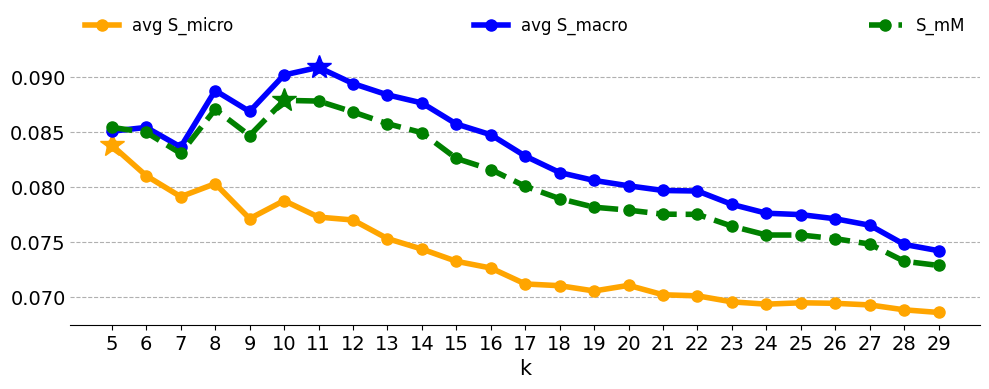

In [8]:
compsilhouette = CompSil(
    data=X_pca,
    ground_truth=None,
    k_values=range(5,30),
    num_samples=20,
    sample_size="auto",
    random_state=0
)

compsilhouette.evaluate()

df_X= compsilhouette.get_results_dataframe()
display(df_X)

compsilhouette.plot_results()

In [9]:
k_smm = compsilhouette.get_optimal_k(use_lcb=False)

### Cluster the Narrative Embeddings with $k$-means and K-Sil



To partition the narrative embeddings into interpretable groups, we apply two clustering approaches using the same number of clusters, $(k = k_{S_{mM}})$, selected by Composite Silhouette ($S_{mM}$) in the previous step:

- $k$-means, which assigns each narrative to the nearest centroid by minimizing within-cluster variance.
- **K-Sil**, a silhouette-driven instance-weighted $k$-means variant that reweights points at each iteration using a centroid-margin proxy for the silhouette score, thereby emphasizing confidently assigned instances and down-weighting ambiguous or noisy boundary points. Centroid updates are computed as softmax-weighted means, with an adaptive temperature that calibrates the sharpness of the weighting scheme using a cluster-balanced, macro-averaged silhouette criterion.

For each method, we:

1. assign a cluster label to every narrative,
2. compute a per-narrative silhouette-based cohesion score,
3. summarize each cluster by:
   - its **size**,
   - its **share** in the corpus,
   - its **mean silhouette score**,
4. visualize:
   - the **relative prevalence** of clusters,
   - the **average geometric cohesion** of each cluster.

The comparison allows us to assess not only how the narratives are distributed across clusters, but also how clearly separated those clusters are in embedding space.


**Model choice:**


We retain the **K-Sil solution** for the downstream analysis because it produces **higher silhouette values**, indicating more coherent and more distinct narrative clusters.

**Next step: diagnosing cluster overlap**


Even when silhouette values are relatively high, some clusters may still be substantively close in meaning.  
For that reason, after selecting the K-Sil solution, we conduct a **cluster-overlap diagnosis** to identify:

- which clusters are nearest to one another,
- which narrative themes are shared across adjacent clusters,
- and which terms or examples make one cluster substantively different from another.

$k$-means Clustering:

,original_index,member_name,...,narratives_label,ksil_score
0,0,κελετσης δημητριου σταυρος,...,7,0.129260
1,9,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),...,0,0.349042
2,10,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),...,8,0.113380
3,11,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),...,7,0.203255
4,29,μυλωνακης αντωνιου αντωνιος,...,3,0.066916


,Size,share,mean_Silhouette
Cluster ID,,,
0,436,9.609874,0.140253
1,580,12.783778,0.098594
2,582,12.827860,0.134730
3,411,9.058849,0.146399
4,173,3.813092,0.296746
5,367,8.089046,0.159262
6,636,14.018074,0.175598
7,548,12.078466,0.122468
8,589,12.982147,0.120812


/tmp/ipykernel_2813/3874797940.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=cluster_profiles_kmeans['narratives_label'], y=cluster_profiles_kmeans['share'],


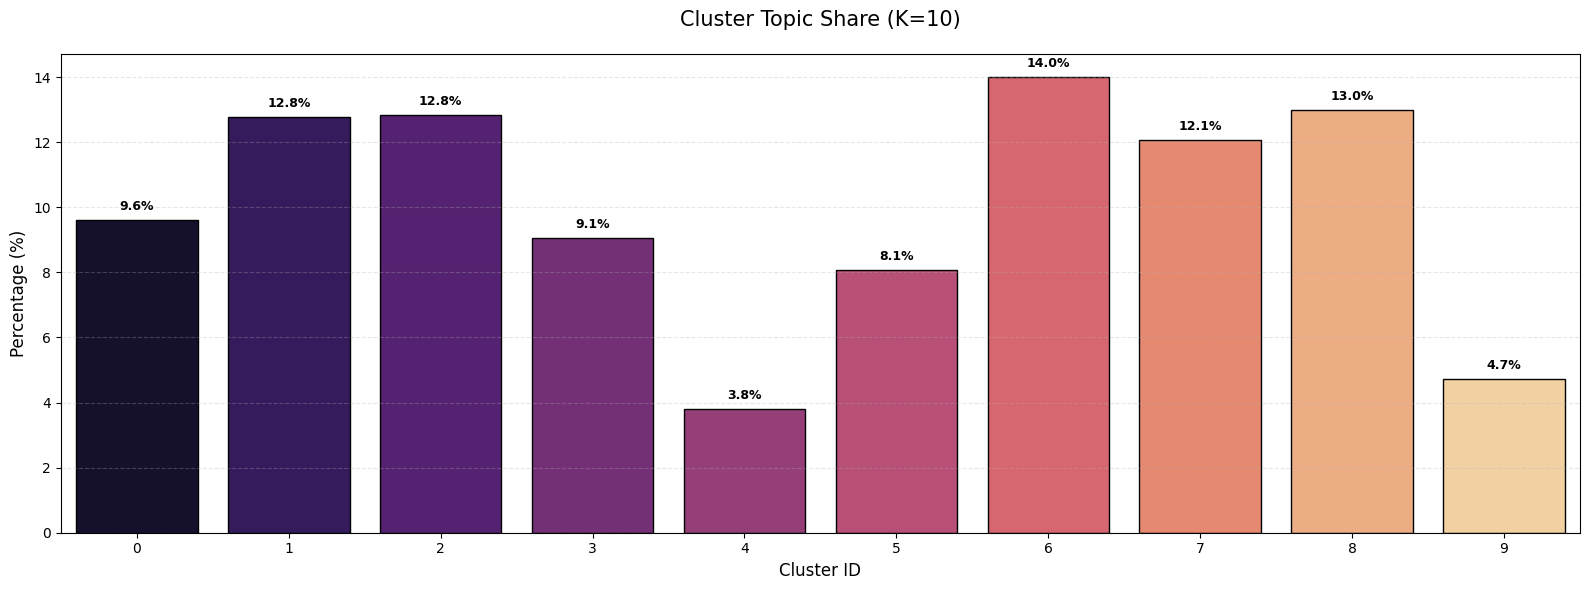

/tmp/ipykernel_2813/3874797940.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x=cluster_profiles_kmeans['narratives_label'], y=cluster_profiles_kmeans['mean_Silhouette'],


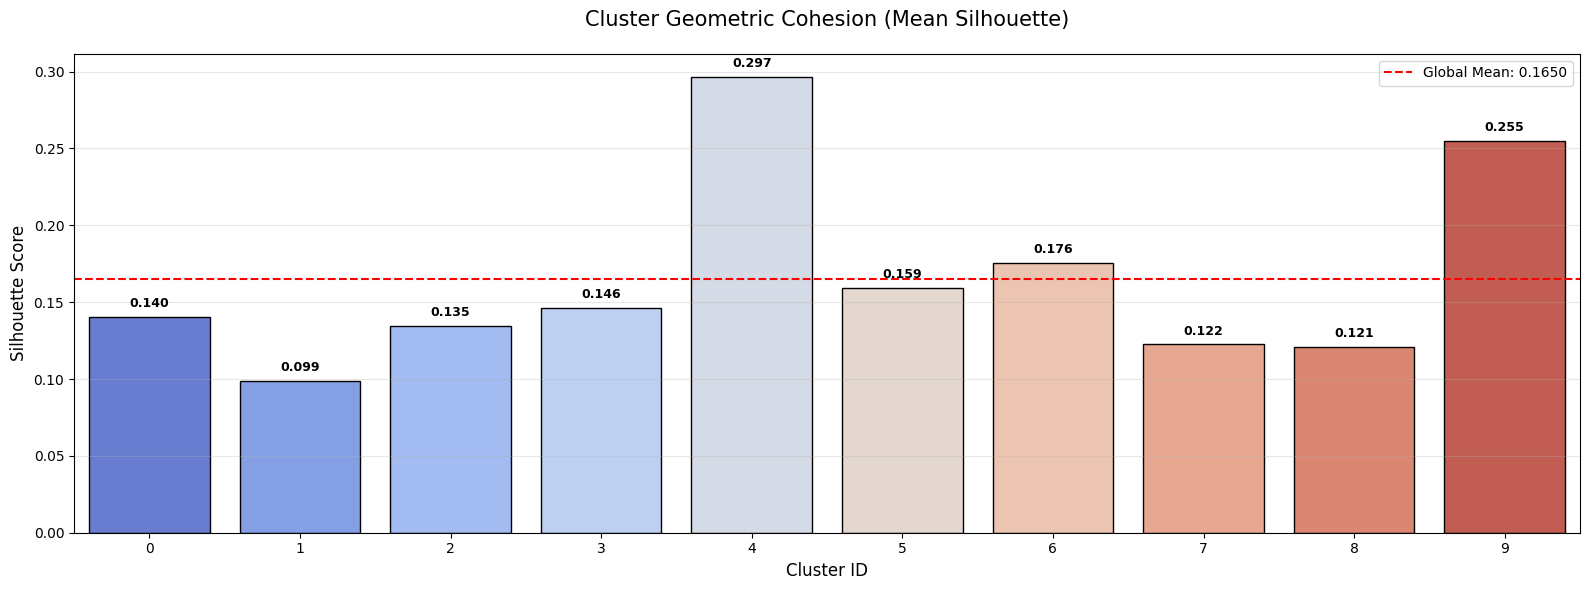

In [10]:
n_clusters = k_smm

kmeans = KMeans(n_clusters=n_clusters, max_iter=100, random_state=0, n_init=100)
cluster_labels = kmeans.fit_predict(X_pca)

new_df_kmeans = df.copy()
new_df_kmeans['narratives_label'] = cluster_labels

sil_vals, _, _ = KSil.sil_scores(X_pca, cluster_labels, kmeans.cluster_centers_)
new_df_kmeans['ksil_score'] = sil_vals

display(new_df_kmeans.head(5))

cluster_profiles_kmeans = new_df_kmeans.groupby('narratives_label').agg(
    Size=('narrative', 'count'),
    mean_Silhouette=('ksil_score', 'mean')
).reset_index()

cluster_profiles_kmeans['share'] = (cluster_profiles_kmeans['Size'] / len(new_df_kmeans)) * 100

final_report_kmeans = cluster_profiles_kmeans.rename(columns={'narratives_label': 'Cluster ID'}).set_index('Cluster ID')
display(final_report_kmeans[['Size', 'share', 'mean_Silhouette']])

plt.figure(figsize=(16, 6))
ax1 = sns.barplot(x=cluster_profiles_kmeans['narratives_label'], y=cluster_profiles_kmeans['share'],
                  palette='magma', edgecolor='black')

for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.title(f'Cluster Topic Share (K={n_clusters})', fontsize=15, pad=20)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 6))
colors = sns.color_palette("coolwarm", len(cluster_profiles_kmeans))
ax2 = sns.barplot(x=cluster_profiles_kmeans['narratives_label'], y=cluster_profiles_kmeans['mean_Silhouette'],
                  palette=colors, edgecolor='black')

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

global_mean = cluster_profiles_kmeans['mean_Silhouette'].mean()
plt.axhline(y=global_mean, color='red', linestyle='--',
            label=f"Global Mean: {global_mean:.4f}")

plt.title(f'Cluster Geometric Cohesion (Mean Silhouette)', fontsize=15, pad=20)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
top_5_raw_kmeans = new_df_kmeans.sort_values('ksil_score', ascending=False).groupby('narratives_label').head(5).reset_index(drop=True)

def format_top_speeches(series):
    formatted = [f"{i+1}. {text}" for i, text in enumerate(series)]
    return " \n\n ".join(formatted)

collapsed_top_df_kmeans = top_5_raw_kmeans.groupby('narratives_label')['narrative'].apply(format_top_speeches).reset_index()

mean_sil_top = top_5_raw_kmeans.groupby('narratives_label')['ksil_score'].mean().reset_index()
collapsed_top_df_kmeans['mean_top_silhouette'] = mean_sil_top['ksil_score']

pd.set_option('display.max_colwidth', None)

display(collapsed_top_df_kmeans)

,narratives_label,narrative,mean_top_silhouette
0,0,1. Government negligence caused preventable railway safety disaster. \n\n 2. Government negligence caused preventable railway safety failures. \n\n 3. Government negligence caused preventable railway safety failures. \n\n 4. Government negligence caused preventable railway safety failures. \n\n 5. Government negligence caused preventable railway safety failures.,0.392255
1,1,1. Government undermining rule of law necessitates Tempi crash accountability \n\n 2. Legal evidence over politics determines Tempi accountability. \n\n 3. Judicial system reliably addresses Tempi crash accountability. \n\n 4. Judicial process ensures accountability for Tempi crash. \n\n 5. Existing constitutional procedures ensure accountability for Tempi crash.,0.241562
2,2,"1. Forming investigative committees obstructs judicial accountability processes. \n\n 2. Investigation structure prevents criminal accountability, ensuring impunity. \n\n 3. Legal procedural constraints impede thorough investigation of ministerial accountability. \n\n 4. Judicial investigation lacks original evidence for accountability. \n\n 5. Government obstructs accountability through manipulated legal proceedings.",0.279079
3,3,1. Government obstructs crash investigation to conceal accountability \n\n 2. Government obstructs crash investigation to evade accountability \n\n 3. Government obstructs thorough crash investigation to evade accountability \n\n 4. Government obstructs crash accountability with partisan report. \n\n 5. Government actions obstructed crash investigation and accountability.,0.357289
4,4,1. Opposition exploits tragedy to construct political narrative. \n\n 2. Opposition exploits tragedy for political survival. \n\n 3. Opposition exploits tragedy to gain political advantage. \n\n 4. Opposition exploits tragedy for political gain. \n\n 5. Opposition exploits tragedy for political gain.,0.589221
5,5,1. Preventable systemic failures caused Tempi train crash. \n\n 2. Government systemic failure caused preventable Tempi disaster. \n\n 3. Systemic governmental incompetence enabled preventable Tempi train disaster. \n\n 4. Enduring political negligence caused preventable Tempi train collision. \n\n 5. Systemic negligence caused preventable Tempi train crash.,0.359459
6,6,1. Government cover-up obstructs Tempi crash accountability. \n\n 2. Government cover-up obstructs Tempi crash accountability. \n\n 3. Government cover-up obstructs Tempi crash accountability. \n\n 4. Government cover-up obstructs Tempi crash accountability. \n\n 5. Government cover-up obstructs Tempi crash accountability.,0.425428
7,7,1. Railway safety prioritized via restructuring and EU-funded modernization. \n\n 2. Railway safety necessitates European-aligned comprehensive systemic reforms. \n\n 3. Enhanced railway safety through institutional reforms and funding. \n\n 4. Railway consolidation and European maintenance contracts prevent systemic failures. \n\n 5. International railway cooperation ensures infrastructure safety upgrades.,0.287566
8,8,1. Systemic state failures and government evasion caused tragedy. \n\n 2. Political theatrics obscure systemic safety failures enabling preventable tragedies \n\n 3. Government must account for systemic failures causing tragedy. \n\n 4. Systemic failures require state correction to prevent future accidents. \n\n 5. Systemic government failure evading accountability for preventable tragedy.,0.323194
9,9,"1. Tempi crash resulted from unresolved systemic failures. \n\n 2. Tempi crash resulted from past policy failures. \n\n 3. Tempi crash constitutes criminal systemic failure. \n\n 4. Tempi crash caused by systemic negligence, cover-up. \n\n 5. Tempi crash resulted from systemic criminal negligence.",0.469917


K-Sil Clustering:

,original_index,member_name,...,narratives_label,ksil_score
0,0,κελετσης δημητριου σταυρος,...,6,0.168038
1,9,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),...,6,0.192090
2,10,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),...,2,0.204370
3,11,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),...,6,0.236294
4,29,μυλωνακης αντωνιου αντωνιος,...,4,0.047772


,Size,share,mean_Silhouette
Cluster ID,,,
0,627,13.819705,0.125480
1,1058,23.319374,0.205621
2,603,13.290721,0.135123
3,236,5.201675,0.261199
4,382,8.419661,0.161394
5,362,7.978841,0.165923
6,837,18.448314,0.170708
7,142,3.129821,0.130954
8,170,3.746969,0.308940


/tmp/ipykernel_2813/3566161901.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=cluster_profiles['narratives_label'], y=cluster_profiles['share'],


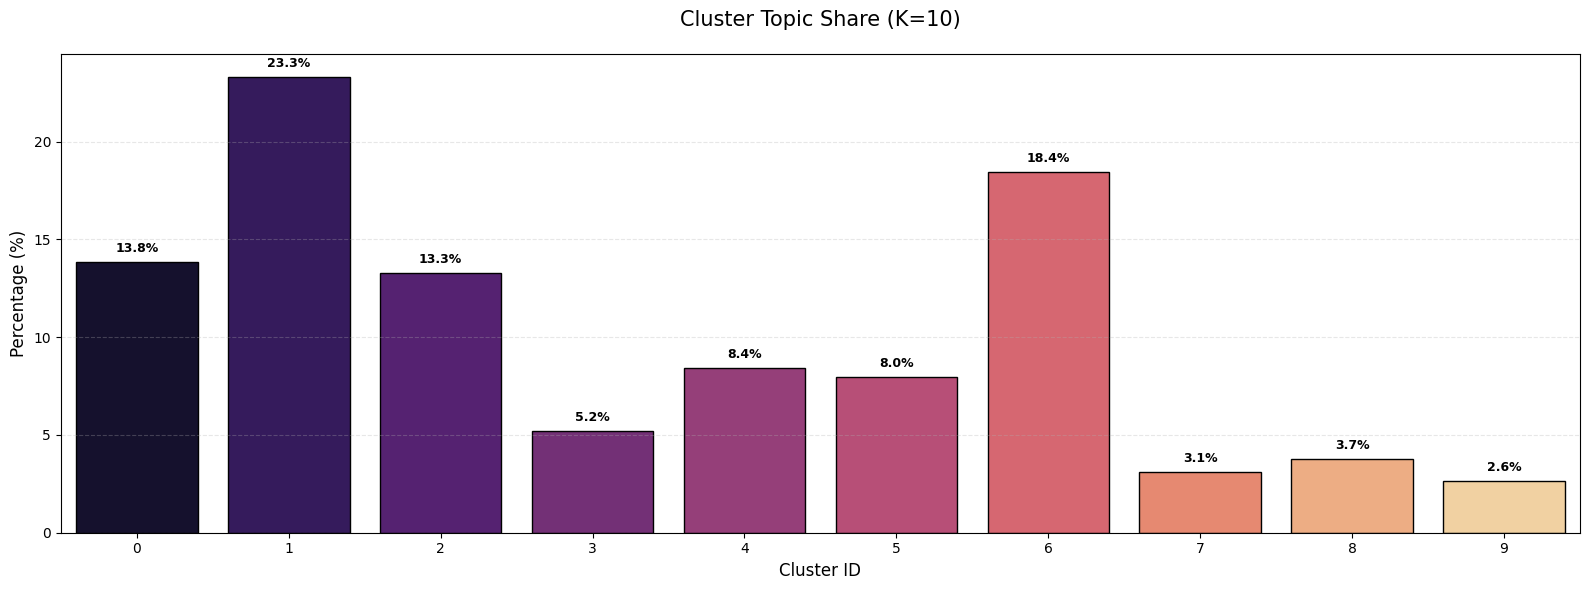

/tmp/ipykernel_2813/3566161901.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x=cluster_profiles['narratives_label'], y=cluster_profiles['mean_Silhouette'],


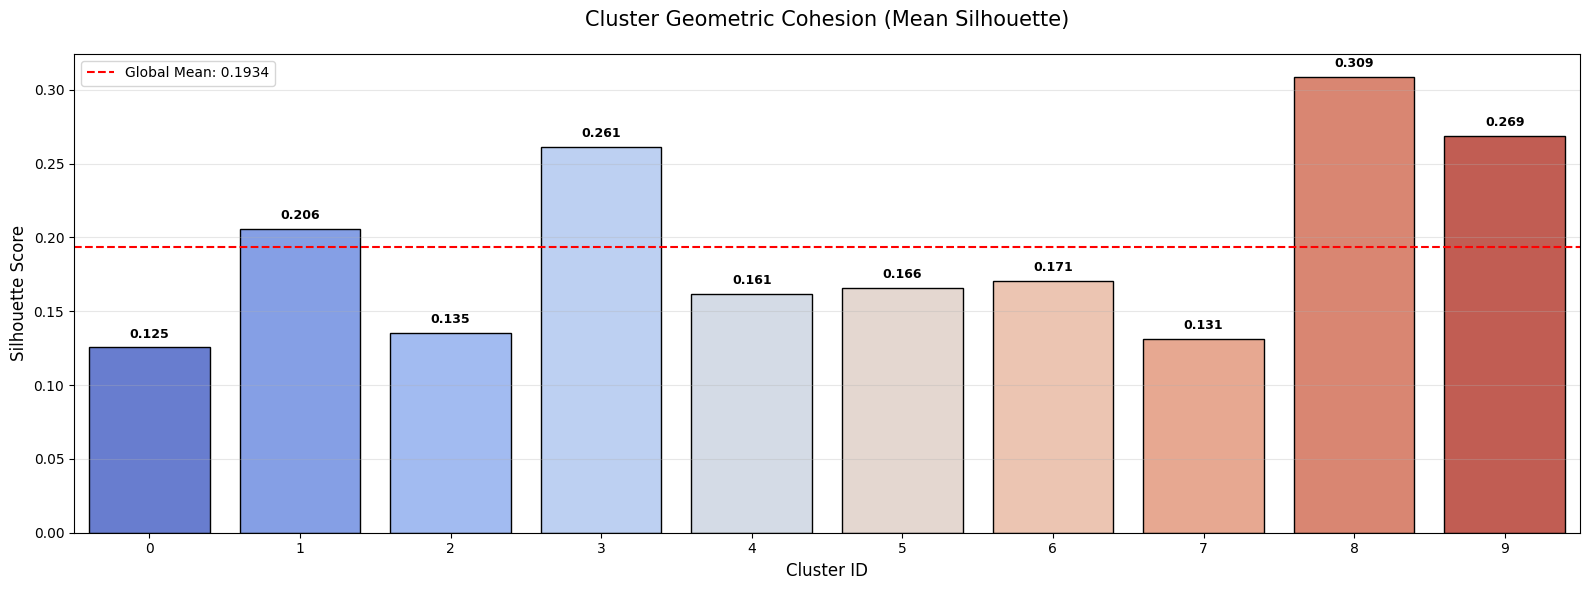

In [12]:
n_clusters = k_smm

ksil = KSil(n_clusters=n_clusters,
            max_iter=100,
            random_state=0,
            init_temperature=2.0,
            learning_rate=0.2,
            tol=1e-4,
            n_init=100,
            n_jobs=-1)

cluster_labels = ksil.fit_predict(X_pca)

new_df = df.copy()
new_df['narratives_label'] = cluster_labels

sil_vals, _, _ = KSil.sil_scores(X_pca, cluster_labels, ksil.cluster_centers_)
new_df['ksil_score'] = sil_vals

display(new_df.head(5))

cluster_profiles = new_df.groupby('narratives_label').agg(
    Size=('narrative', 'count'),
    mean_Silhouette=('ksil_score', 'mean')
).reset_index()

cluster_profiles['share'] = (cluster_profiles['Size'] / len(new_df)) * 100

final_report = cluster_profiles.rename(columns={'narratives_label': 'Cluster ID'}).set_index('Cluster ID')
display(final_report[['Size', 'share', 'mean_Silhouette']])

plt.figure(figsize=(16, 6))
ax1 = sns.barplot(x=cluster_profiles['narratives_label'], y=cluster_profiles['share'],
                  palette='magma', edgecolor='black')

for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.title(f'Cluster Topic Share (K={n_clusters})', fontsize=15, pad=20)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 6))
colors = sns.color_palette("coolwarm", len(cluster_profiles))
ax2 = sns.barplot(x=cluster_profiles['narratives_label'], y=cluster_profiles['mean_Silhouette'],
                  palette=colors, edgecolor='black')

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

global_mean = cluster_profiles['mean_Silhouette'].mean()
plt.axhline(y=global_mean, color='red', linestyle='--',
            label=f"Global Mean: {global_mean:.4f}")

plt.title(f'Cluster Geometric Cohesion (Mean Silhouette)', fontsize=15, pad=20)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
top_5_raw = new_df.sort_values('ksil_score', ascending=False).groupby('narratives_label').head(5).reset_index(drop=True)

def format_top_speeches(series):
    formatted = [f"{i+1}. {text}" for i, text in enumerate(series)]
    return " \n\n ".join(formatted)

collapsed_top_df = top_5_raw.groupby('narratives_label')['narrative'].apply(format_top_speeches).reset_index()

mean_sil_top = top_5_raw.groupby('narratives_label')['ksil_score'].mean().reset_index()
collapsed_top_df['mean_top_silhouette'] = mean_sil_top['ksil_score']


pd.set_option('display.max_colwidth', None)

display(collapsed_top_df)

,narratives_label,narrative,mean_top_silhouette
0,0,"1. Forming investigative committees obstructs judicial accountability processes. \n\n 2. Judicial investigation lacks original evidence for accountability. \n\n 3. Investigation structure prevents criminal accountability, ensuring impunity. \n\n 4. Judicial accountability required for manipulated investigative report \n\n 5. Government assumes political accountability amid independent judicial investigation.",0.302699
1,1,1. Government-led cover-up obstructs Tempi crash accountability. \n\n 2. Government-led cover-up obstructs Tempi crash accountability. \n\n 3. Government obstructs investigation into Tempi crash accountability. \n\n 4. Government obstructs investigation into Tempi crash accountability. \n\n 5. Government obstructs justice for Tempi crash accountability.,0.449298
2,2,1. Systemic negligence and temporary fixes cause preventable disasters. \n\n 2. Systemic governance failures caused preventable disaster \n\n 3. Political theatrics obscure systemic safety failures enabling preventable tragedies \n\n 4. Government inaction on systemic failures causes preventable deaths. \n\n 5. Systemic governance failures caused preventable disasters via negligence.,0.385784
3,3,1. Tempi crash constitutes criminal systemic failure. \n\n 2. Tempi crash resulted from past policy failures. \n\n 3. Tempi crash resulted from unresolved systemic failures. \n\n 4. Tempi crash resulted from systemic criminal negligence. \n\n 5. Tempi crash resulted from systemic governance failures.,0.492649
4,4,1. Government obstructs crash investigation to conceal accountability \n\n 2. Government obstructs crash investigation to evade accountability \n\n 3. Government obstructs thorough crash investigation to evade accountability \n\n 4. Government obstructs crash accountability with partisan report. \n\n 5. Government obstructs crash investigation to avoid accountability.,0.411278
5,5,1. Infrastructure negligence caused preventable Tempi train crash. \n\n 2. Preventable systemic failures caused Tempi train crash. \n\n 3. Government's systemic negligence caused preventable Tempi railway disaster. \n\n 4. Systemic governmental incompetence enabled preventable Tempi train disaster. \n\n 5. Systemic negligence caused preventable Tempi train crash.,0.418052
6,6,1. Railway safety remains unsecured due to governmental failure. \n\n 2. Railway safety systems neglected despite prior union warnings. \n\n 3. Government neglect caused railway safety system collapse. \n\n 4. Railway safety system remains non-operational despite government assurances. \n\n 5. Railway safety not contingent on specific system's existence.,0.375211
7,7,1. Legal framework shields ministers from Tempi crash accountability. \n\n 2. Legal amendments shield ministers from Tempi crash liability. \n\n 3. Constitutional procedures preclude ministerial criminal liability for Tempi. \n\n 4. Ministerial omissions require legal accountability for train crash. \n\n 5. Minister shielded from judicial accountability in Tempi crash.,0.299440
8,8,1. Opposition exploits tragedy for political survival. \n\n 2. Opposition exploits tragedy to construct political narrative. \n\n 3. Opposition exploits tragedy for political gain. \n\n 4. Opposition exploits tragedy for political gain. \n\n 5. Opposition exploits tragedy for political gain.,0.645918
9,9,1. Railway privatization without investment guarantees caused safety failures. \n\n 2. Privatization-driven railway fragmentation caused systemic safety failures. \n\n 3. Privatization caused systemic railway safety failures. \n\n 4. Privatization caused systemic railway safety failures. \n\n 5. Railway privatization caused systemic safety failures.,0.500188


**We keep the higher silhouette (more distinct) K-Sil results and we perform a cluster overlap diagnosis.**

### Cluster-Overlap Diagnosis

In [14]:
text_col = 'narrative'
label_col = 'narratives_label'

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

# Cluster centroids in PCA space
centroids = (
    new_df
    .groupby(label_col)
    .apply(lambda g: np.mean(X_pca[g.index], axis=0))
)

centroid_matrix = np.vstack(centroids.values)
cluster_ids = centroids.index.to_list()

# Cosine similarity between centroids
sim_matrix = cosine_similarity(centroid_matrix)
sim_df = pd.DataFrame(sim_matrix, index=cluster_ids, columns=cluster_ids)

# Remove self-similarity when searching nearest neighbor
np.fill_diagonal(sim_matrix, -np.inf)

nearest_cluster = sim_matrix.argmax(axis=1)
nearest_similarity = sim_matrix.max(axis=1)

nearest_clusters_df = pd.DataFrame({
    'cluster': cluster_ids,
    'nearest_cluster': [cluster_ids[i] for i in nearest_cluster],
    'centroid_cosine_similarity': nearest_similarity
}).sort_values('centroid_cosine_similarity', ascending=False)

display(nearest_clusters_df)

/tmp/ipykernel_2813/1597526775.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.mean(X_pca[g.index], axis=0))


,cluster,nearest_cluster,centroid_cosine_similarity
6,6,9,0.589880
9,9,6,0.589880
5,5,1,0.327219
1,1,5,0.327219
0,0,2,0.316746
2,2,0,0.316746
3,3,1,0.300781
7,7,0,0.264993
4,4,0,0.226453
8,8,0,0.210014


In [15]:
def get_top_examples(df, cluster_id, text_col='narrative', score_col='ksil_score', n=10):
    return (
        df[df['narratives_label'] == cluster_id]
        .sort_values(score_col, ascending=False)
        [[text_col, score_col]]
        .head(n)
        .reset_index(drop=True)
    )

# Example usage
cluster_a = 1
cluster_b = int(nearest_clusters_df.loc[nearest_clusters_df['cluster'] == cluster_a, 'nearest_cluster'].iloc[0])

print(f"Cluster {cluster_a} vs nearest cluster {cluster_b}")

display(get_top_examples(new_df, cluster_a, n=10))
display(get_top_examples(new_df, cluster_b, n=10))

Cluster 1 vs nearest cluster 5


,narrative,ksil_score
0,Government-led cover-up obstructs Tempi crash accountability.,0.450107
1,Government-led cover-up obstructs Tempi crash accountability.,0.450107
2,Government obstructs investigation into Tempi crash accountability.,0.449636
3,Government obstructs investigation into Tempi crash accountability.,0.449636
4,Government obstructs justice for Tempi crash accountability.,0.447002
5,Government obstructs justice for Tempi crash accountability.,0.447002
6,Government obstructs Tempi crash accountability via institutional manipulation.,0.439970
7,Government cover-up obstructs Tempi crash accountability.,0.439188
8,Government cover-up obstructs Tempi crash accountability.,0.439188
9,Government cover-up obstructs Tempi crash accountability.,0.439188


,narrative,ksil_score
0,Infrastructure negligence caused preventable Tempi train crash.,0.436304
1,Preventable systemic failures caused Tempi train crash.,0.420389
2,Government's systemic negligence caused preventable Tempi railway disaster.,0.415369
3,Systemic governmental incompetence enabled preventable Tempi train disaster.,0.411508
4,Systemic negligence caused preventable Tempi train crash.,0.406689
5,Systemic government failures caused preventable Tempi train disaster.,0.401371
6,Enduring political negligence caused preventable Tempi train collision.,0.396074
7,Systemic governance failures caused preventable Tempi train crash.,0.386841
8,Government systemic failure caused preventable Tempi disaster.,0.385283
9,Government negligence caused preventable Tempi train tragedy,0.379026


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

def contrastive_terms(df, cluster_a, cluster_b, text_col='narrative',
                      ngram_range=(1,2), min_df=2, top_n=20):

    subset = df[df['narratives_label'].isin([cluster_a, cluster_b])].copy()
    texts = subset[text_col].fillna("").astype(str).tolist()

    vectorizer = TfidfVectorizer(
        stop_words='english',
        ngram_range=ngram_range,
        min_df=min_df,
        max_df=0.9
    )

    X = vectorizer.fit_transform(texts)
    features = np.array(vectorizer.get_feature_names_out())

    subset = subset.reset_index(drop=True)
    mask_a = subset['narratives_label'] == cluster_a
    mask_b = subset['narratives_label'] == cluster_b

from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import pandas as pd

def contrastive_terms(df, cluster_a, cluster_b, text_col='narrative',
                      label_col='narratives_label',
                      ngram_range=(1, 2), min_df=2, top_n=20):

    subset = df[df[label_col].isin([cluster_a, cluster_b])].copy()
    subset = subset.reset_index(drop=True)

    texts = subset[text_col].fillna("").astype(str).tolist()

    vectorizer = TfidfVectorizer(
        stop_words='english',
        ngram_range=ngram_range,
        min_df=min_df,
        max_df=0.9
    )

    X = vectorizer.fit_transform(texts)
    features = np.array(vectorizer.get_feature_names_out())

    mask_a = (subset[label_col] == cluster_a).to_numpy()
    mask_b = (subset[label_col] == cluster_b).to_numpy()

    mean_a = np.asarray(X[mask_a].mean(axis=0)).ravel()
    mean_b = np.asarray(X[mask_b].mean(axis=0)).ravel()

    diff_a = mean_a - mean_b
    diff_b = mean_b - mean_a

    top_a_idx = np.argsort(diff_a)[::-1][:top_n]
    top_b_idx = np.argsort(diff_b)[::-1][:top_n]

    top_a = pd.DataFrame({
        'term': features[top_a_idx],
        'contrast_score': diff_a[top_a_idx]
    })

    top_b = pd.DataFrame({
        'term': features[top_b_idx],
        'contrast_score': diff_b[top_b_idx]
    })

    return top_a, top_b

In [17]:
top_a, top_b = contrastive_terms(new_df, cluster_a=1, cluster_b=4, top_n=15)

print("Terms more characteristic of cluster 1:")
display(top_a)

print("Terms more characteristic of cluster 4:")
display(top_b)

Terms more characteristic of cluster 1:


,term,contrast_score
0,tempi,0.100736
1,tempi crash,0.093802
2,obstructs tempi,0.035406
3,cover,0.031637
4,government cover,0.027091
5,tempi investigation,0.020062
6,cover tempi,0.018891
7,accountability tempi,0.018751
8,obstructs,0.016917
9,obstructed tempi,0.016020


Terms more characteristic of cluster 4:


,term,contrast_score
0,train,0.048744
1,train crash,0.048647
2,post crash,0.023587
3,post,0.022323
4,crash investigation,0.019741
5,evade crash,0.018779
6,obstructs crash,0.017835
7,crash,0.016143
8,accountability train,0.015447
9,safety,0.014321


In [18]:
all_cluster_diagnostics = []

for _, row in nearest_clusters_df.iterrows():
    c1 = int(row['cluster'])
    c2 = int(row['nearest_cluster'])

    top_c1, top_c2 = contrastive_terms(new_df, c1, c2, top_n=10)

    all_cluster_diagnostics.append({
        'cluster': c1,
        'nearest_cluster': c2,
        'centroid_cosine_similarity': row['centroid_cosine_similarity'],
        'distinctive_terms_cluster': ", ".join(top_c1['term'].head(8).tolist()),
        'distinctive_terms_nearest': ", ".join(top_c2['term'].head(8).tolist())
    })

diagnostics_df = pd.DataFrame(all_cluster_diagnostics).sort_values(
    'centroid_cosine_similarity', ascending=False
)

display(diagnostics_df)

,cluster,nearest_cluster,...,distinctive_terms_cluster,distinctive_terms_nearest
0,6,9,...,"government, railway safety, negligence, train, government negligence, reforms, rail safety, negligence caused","privatization, privatization caused, railway privatization, caused systemic, caused, safety failures, failures, systemic safety"
1,9,6,...,"privatization, privatization caused, railway privatization, caused systemic, caused, safety failures, failures, systemic safety","government, railway safety, negligence, train, government negligence, reforms, rail safety, negligence caused"
2,5,1,...,"caused, preventable, preventable tempi, caused preventable, safety, train, caused tempi, tempi train","accountability, crash accountability, tempi crash, investigation, government, obstructs, cover, obstructs tempi"
3,1,5,...,"accountability, crash accountability, tempi crash, investigation, government, obstructs, cover, obstructs tempi","caused, preventable, preventable tempi, caused preventable, safety, train, caused tempi, tempi train"
4,0,2,...,"accountability, investigation, judicial, political, criminal, tempi, justice, legal","systemic, safety, preventable, failures, caused, caused preventable, safety failures, disaster"
5,2,0,...,"systemic, safety, preventable, failures, caused, caused preventable, safety failures, disaster","accountability, investigation, judicial, political, criminal, tempi, justice, legal"
6,3,1,...,"systemic, crash caused, failures, resulted, crash resulted, requires, crash necessitates, caused","government, crash accountability, accountability, obstructs, obstructs tempi, government cover, investigation, cover"
7,7,0,...,"crash, ministerial, tempi crash, tempi, minister, crash accountability, ministers, ministerial accountability","investigation, government, political, judicial, justice, evidence, systemic, institutional"
8,4,0,...,"crash, crash accountability, train crash, train, crash investigation, post crash, post, government","tempi, political, judicial, criminal, legal, justice, political accountability, tempi accountability"
9,8,0,...,"opposition, tragedy, exploits, opposition exploits, exploits tragedy, tempi tragedy, exploits tempi, gain","accountability, investigation, government, judicial, criminal, obstructs, committee, responsibility"


In [19]:
def get_representative_subset(df, cluster_id, top_n=30, score_col='ksil_score'):
    return (
        df[df['narratives_label'] == cluster_id]
        .sort_values(score_col, ascending=False)
        .head(top_n)
    )

def contrastive_terms_representative(df, cluster_a, cluster_b, text_col='narrative',
                                     score_col='ksil_score', rep_n=30,
                                     ngram_range=(1,2), min_df=2, top_n=20):

    sub_a = get_representative_subset(df, cluster_a, top_n=rep_n, score_col=score_col)
    sub_b = get_representative_subset(df, cluster_b, top_n=rep_n, score_col=score_col)
    subset = pd.concat([sub_a, sub_b], axis=0).copy()

    texts = subset[text_col].fillna("").astype(str).tolist()

    vectorizer = TfidfVectorizer(
        stop_words='english',
        ngram_range=ngram_range,
        min_df=min_df,
        max_df=0.9
    )

    X = vectorizer.fit_transform(texts)
    features = np.array(vectorizer.get_feature_names_out())

    subset = subset.reset_index(drop=True)
    mask_a = (subset['narratives_label'] == cluster_a).to_numpy()
    mask_b = (subset['narratives_label'] == cluster_b).to_numpy()

    mean_a = np.asarray(X[mask_a].mean(axis=0)).ravel()
    mean_b = np.asarray(X[mask_b].mean(axis=0)).ravel()

    diff_a = mean_a - mean_b
    diff_b = mean_b - mean_a

    top_a_idx = np.argsort(diff_a)[::-1][:top_n]
    top_b_idx = np.argsort(diff_b)[::-1][:top_n]

    top_a = pd.DataFrame({
        'term': features[top_a_idx],
        'contrast_score': diff_a[top_a_idx]
    })
    top_b = pd.DataFrame({
        'term': features[top_b_idx],
        'contrast_score': diff_b[top_b_idx]
    })

    return top_a, top_b

In [20]:
def flag_candidate_merge(similarity, top_terms_a, top_terms_b, sim_threshold=0.90):
    if similarity >= sim_threshold:
        return "review_merge"
    return "keep"

In [21]:
def compare_clusters_report(df, cluster_a, cluster_b, text_col='narrative', score_col='ksil_score'):
    top_a, top_b = contrastive_terms_representative(df, cluster_a, cluster_b,
                                                    text_col=text_col,
                                                    score_col=score_col,
                                                    rep_n=30,
                                                    top_n=10)

    examples_a = get_top_examples(df, cluster_a, text_col=text_col, score_col=score_col, n=5)
    examples_b = get_top_examples(df, cluster_b, text_col=text_col, score_col=score_col, n=5)

    return {
        'cluster_a': cluster_a,
        'cluster_b': cluster_b,
        'distinctive_terms_a': top_a,
        'distinctive_terms_b': top_b,
        'examples_a': examples_a,
        'examples_b': examples_b
    }

In [22]:
report = compare_clusters_report(new_df, 1, 4)

print("Distinctive terms for cluster 1")
display(report['distinctive_terms_a'])

print("Distinctive terms for cluster 4")
display(report['distinctive_terms_b'])

print("Top examples cluster 1")
display(report['examples_a'])

print("Top examples cluster 4")
display(report['examples_b'])

Distinctive terms for cluster 1


,term,contrast_score
0,tempi crash,0.279428
1,tempi,0.279428
2,obstructs tempi,0.229034
3,government cover,0.211394
4,cover,0.193099
5,cover obstructs,0.192136
6,crash accountability,0.126246
7,accountability investigation,0.087036
8,obstructs,0.079973
9,cover obstructed,0.065096


Distinctive terms for cluster 4


,term,contrast_score
0,evade,0.158355
1,investigation evade,0.144226
2,obstructs crash,0.133813
3,crash investigation,0.131029
4,evade accountability,0.117942
5,investigation,0.090881
6,evade crash,0.076051
7,avoid accountability,0.064077
8,avoid,0.064077
9,obstructed crash,0.063179


Top examples cluster 1


,narrative,ksil_score
0,Government-led cover-up obstructs Tempi crash accountability.,0.450107
1,Government-led cover-up obstructs Tempi crash accountability.,0.450107
2,Government obstructs investigation into Tempi crash accountability.,0.449636
3,Government obstructs investigation into Tempi crash accountability.,0.449636
4,Government obstructs justice for Tempi crash accountability.,0.447002


Top examples cluster 4


,narrative,ksil_score
0,Government obstructs crash investigation to conceal accountability,0.438034
1,Government obstructs crash investigation to evade accountability,0.421677
2,Government obstructs thorough crash investigation to evade accountability,0.413857
3,Government obstructs crash accountability with partisan report.,0.391488
4,Government obstructs crash investigation to avoid accountability.,0.391334


In [23]:
actor_dict = {
    'government': ['government', 'state', 'administration'],
    'judiciary': ['judicial', 'judiciary', 'court', 'judge'],
    'opposition': ['opposition', 'pasok', 'syriza'],
    'ministers': ['minister', 'ministerial'],
    'eu': ['eu', 'european', 'directive', 'regulation']
}

mechanism_dict = {
    'coverup': ['cover-up', 'coverup', 'conceal', 'hide', 'tamper'],
    'obstruction': ['obstruct', 'block', 'delay', 'manipulate'],
    'negligence': ['negligence', 'neglect', 'failure', 'inaction'],
    'privatization': ['privatization', 'fragmentation', 'private'],
    'immunity': ['immunity', 'constitutional', 'shield', 'liability']
}

In [24]:
def show_cluster_pair(df, cluster_a, cluster_b, top_n_terms=10, top_n_examples=5):
    top_a, top_b = contrastive_terms_representative(
        df, cluster_a, cluster_b, rep_n=30, top_n=top_n_terms
    )

    ex_a = get_top_examples(df, cluster_a, n=top_n_examples)
    ex_b = get_top_examples(df, cluster_b, n=top_n_examples)

    print(f"\n=== Cluster {cluster_a} distinctive terms ===")
    display(top_a)

    print(f"\n=== Cluster {cluster_b} distinctive terms ===")
    display(top_b)

    print(f"\n=== Cluster {cluster_a} top examples ===")
    display(ex_a)

    print(f"\n=== Cluster {cluster_b} top examples ===")
    display(ex_b)

In [25]:
show_cluster_pair(new_df, 1, 4)
show_cluster_pair(new_df, 0, 9)
show_cluster_pair(new_df, 2, 5)
show_cluster_pair(new_df, 6, 3)
show_cluster_pair(new_df, 8, 4)


=== Cluster 1 distinctive terms ===


,term,contrast_score
0,tempi crash,0.279428
1,tempi,0.279428
2,obstructs tempi,0.229034
3,government cover,0.211394
4,cover,0.193099
5,cover obstructs,0.192136
6,crash accountability,0.126246
7,accountability investigation,0.087036
8,obstructs,0.079973
9,cover obstructed,0.065096



=== Cluster 4 distinctive terms ===


,term,contrast_score
0,evade,0.158355
1,investigation evade,0.144226
2,obstructs crash,0.133813
3,crash investigation,0.131029
4,evade accountability,0.117942
5,investigation,0.090881
6,evade crash,0.076051
7,avoid accountability,0.064077
8,avoid,0.064077
9,obstructed crash,0.063179



=== Cluster 1 top examples ===


...

,term,contrast_score
0,crash,0.216863
1,accountability,0.191977
2,investigation,0.180968
3,government,0.171035
4,obstructs,0.146144
5,crash investigation,0.144529
6,government obstructs,0.138608
7,evade,0.134737
8,investigation evade,0.121236
9,crash accountability,0.116427



=== Cluster 8 top examples ===


,narrative,ksil_score
0,Opposition exploits tragedy for political survival.,0.655397
1,Opposition exploits tragedy to construct political narrative.,0.647401
2,Opposition exploits tragedy for political gain.,0.642263
3,Opposition exploits tragedy for political gain.,0.642263
4,Opposition exploits tragedy for political gain.,0.642263



=== Cluster 4 top examples ===


,narrative,ksil_score
0,Government obstructs crash investigation to conceal accountability,0.438034
1,Government obstructs crash investigation to evade accountability,0.421677
2,Government obstructs thorough crash investigation to evade accountability,0.413857
3,Government obstructs crash accountability with partisan report.,0.391488
4,Government obstructs crash investigation to avoid accountability.,0.391334


In [26]:
cluster_label_map = {
    0: "Judicial and procedural obstacles to accountability",
    1: "Government cover-up of Tempi accountability",
    2: "Systemic governance failures caused preventable disaster",
    3: "Tempi crash resulted from systemic criminal failure",
    4: "Government obstructs crash investigation to evade accountability",
    5: "Negligence caused the preventable Tempi train crash",
    6: "Railway safety remains neglected and unsecured",
    7: "Legal framework shields ministers from accountability",
    8: "Opposition exploits the tragedy for political gain",
    9: "Railway privatization caused systemic safety failures"
}

In [27]:
new_df["narrative_label_clean"] = new_df["narratives_label"].map(cluster_label_map)

### Taxonomies

In [28]:
collapsed_top_df["narrative_label_clean"] = collapsed_top_df["narratives_label"].map(cluster_label_map)
display(collapsed_top_df[["narratives_label", "narrative_label_clean", "narrative", "mean_top_silhouette"]])

,narratives_label,narrative_label_clean,narrative,mean_top_silhouette
0,0,Judicial and procedural obstacles to accountability,"1. Forming investigative committees obstructs judicial accountability processes. \n\n 2. Judicial investigation lacks original evidence for accountability. \n\n 3. Investigation structure prevents criminal accountability, ensuring impunity. \n\n 4. Judicial accountability required for manipulated investigative report \n\n 5. Government assumes political accountability amid independent judicial investigation.",0.302699
1,1,Government cover-up of Tempi accountability,1. Government-led cover-up obstructs Tempi crash accountability. \n\n 2. Government-led cover-up obstructs Tempi crash accountability. \n\n 3. Government obstructs investigation into Tempi crash accountability. \n\n 4. Government obstructs investigation into Tempi crash accountability. \n\n 5. Government obstructs justice for Tempi crash accountability.,0.449298
2,2,Systemic governance failures caused preventable disaster,1. Systemic negligence and temporary fixes cause preventable disasters. \n\n 2. Systemic governance failures caused preventable disaster \n\n 3. Political theatrics obscure systemic safety failures enabling preventable tragedies \n\n 4. Government inaction on systemic failures causes preventable deaths. \n\n 5. Systemic governance failures caused preventable disasters via negligence.,0.385784
3,3,Tempi crash resulted from systemic criminal failure,1. Tempi crash constitutes criminal systemic failure. \n\n 2. Tempi crash resulted from past policy failures. \n\n 3. Tempi crash resulted from unresolved systemic failures. \n\n 4. Tempi crash resulted from systemic criminal negligence. \n\n 5. Tempi crash resulted from systemic governance failures.,0.492649
4,4,Government obstructs crash investigation to evade accountability,1. Government obstructs crash investigation to conceal accountability \n\n 2. Government obstructs crash investigation to evade accountability \n\n 3. Government obstructs thorough crash investigation to evade accountability \n\n 4. Government obstructs crash accountability with partisan report. \n\n 5. Government obstructs crash investigation to avoid accountability.,0.411278
5,5,Negligence caused the preventable Tempi train crash,1. Infrastructure negligence caused preventable Tempi train crash. \n\n 2. Preventable systemic failures caused Tempi train crash. \n\n 3. Government's systemic negligence caused preventable Tempi railway disaster. \n\n 4. Systemic governmental incompetence enabled preventable Tempi train disaster. \n\n 5. Systemic negligence caused preventable Tempi train crash.,0.418052
6,6,Railway safety remains neglected and unsecured,1. Railway safety remains unsecured due to governmental failure. \n\n 2. Railway safety systems neglected despite prior union warnings. \n\n 3. Government neglect caused railway safety system collapse. \n\n 4. Railway safety system remains non-operational despite government assurances. \n\n 5. Railway safety not contingent on specific system's existence.,0.375211
7,7,Legal framework shields ministers from accountability,1. Legal framework shields ministers from Tempi crash accountability. \n\n 2. Legal amendments shield ministers from Tempi crash liability. \n\n 3. Constitutional procedures preclude ministerial criminal liability for Tempi. \n\n 4. Ministerial omissions require legal accountability for train crash. \n\n 5. Minister shielded from judicial accountability in Tempi crash.,0.299440
8,8,Opposition exploits the tragedy for political gain,1. Opposition exploits tragedy for political survival. \n\n 2. Opposition exploits tragedy to construct political narrative. \n\n 3. Opposition exploits tragedy for political gain. \n\n 4. Opposition exploits tragedy for political gain. \n\n 5. Opposition exploits tragedy for political gain.,0.645918
9,9,Railway privatization caused systemic safety failures,1. Railway privatization without investment guarantees caused s

In [29]:
pairwise_notes = pd.DataFrame([
    {
        "cluster_a": 1,
        "cluster_b": 4,
        "difference": "Cluster 1 emphasizes cover-up/concealment; Cluster 4 emphasizes obstruction of the investigation to evade accountability.",
        "decision": "keep separate"
    },
    {
        "cluster_a": 2,
        "cluster_b": 5,
        "difference": "Cluster 2 is abstract/systemic; Cluster 5 is Tempi-specific and crash-causal.",
        "decision": "keep separate"
    },
    {
        "cluster_a": 6,
        "cluster_b": 3,
        "difference": "Cluster 6 concerns ongoing railway safety neglect; Cluster 3 interprets Tempi as systemic criminal failure.",
        "decision": "keep separate"
    }
])

display(pairwise_notes)

,cluster_a,cluster_b,difference,decision
0,1,4,Cluster 1 emphasizes cover-up/concealment; Cluster 4 emphasizes obstruction of the investigation to evade accountability.,keep separate
1,2,5,Cluster 2 is abstract/systemic; Cluster 5 is Tempi-specific and crash-causal.,keep separate
2,6,3,Cluster 6 concerns ongoing railway safety neglect; Cluster 3 interprets Tempi as systemic criminal failure.,keep separate


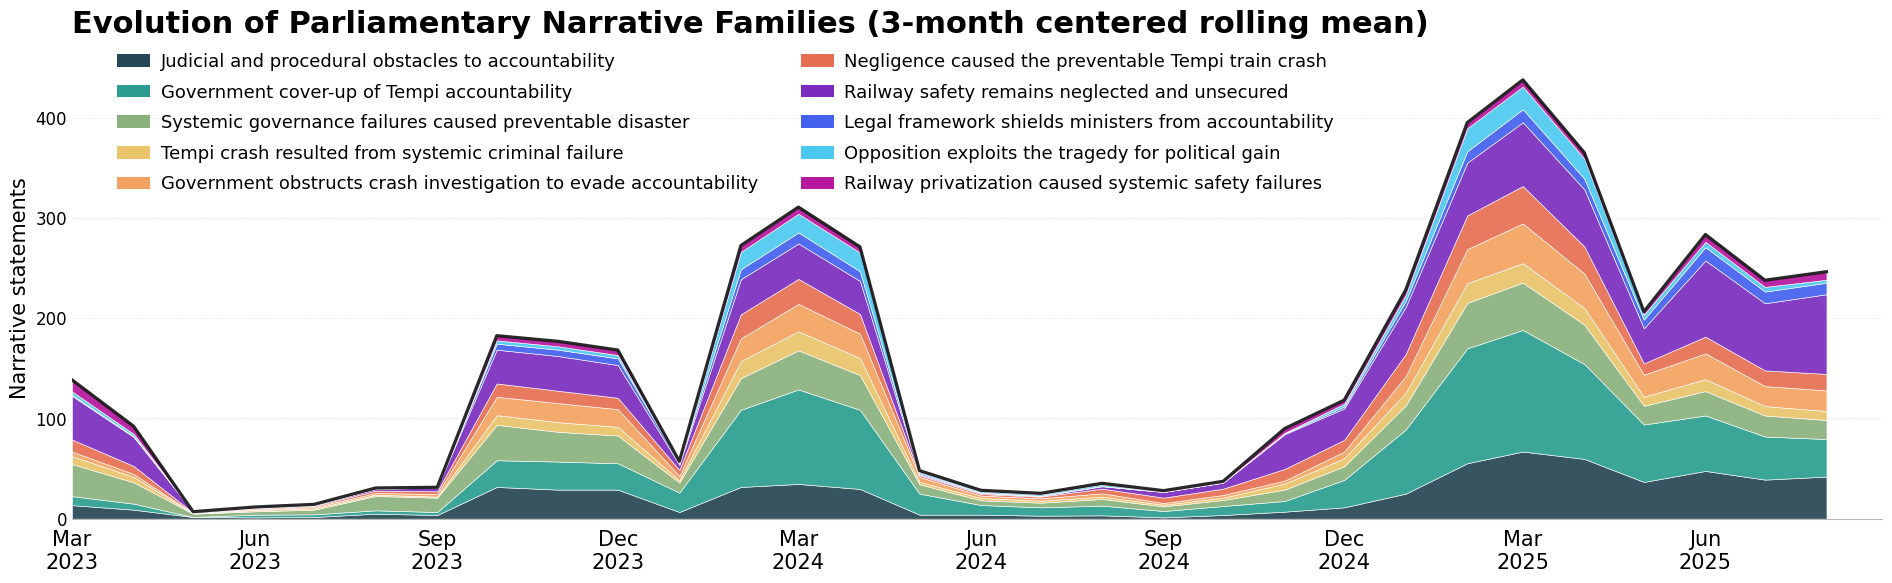

Date column used: sitting_date
Period: 2023-03 to 2025-08
Saved PDF: /content/cart/narrative_clusters_over_time.pdf
Saved PNG: /content/cart/narrative_clusters_over_time.png


In [30]:
# ============================================================
# Temporal evolution of the final K-Sil narrative clusters
# Publication-ready wide stacked time series
# Requires: new_df and cluster_label_map from the cells above
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from pathlib import Path

# ---------- Settings ----------
FREQ = "MS"                 # monthly aggregation
ROLLING_MONTHS = 3          # 1 = raw counts; use 2 or 3 for smoothing
OUTPUT_STEM = "narrative_clusters_over_time"
FIGSIZE = (20, 7.2)
DPI = 600

# ---------- Validation ----------
if "new_df" not in globals():
    raise NameError(
        "Run the K-Sil clustering cell first so that `new_df` exists."
    )

plot_df = new_df.copy()

# Automatically detect the date column
date_candidates = [
    "sitting_date",
    "Sitting_Date",
    "date",
    "Date",
    "speech_date",
    "session_date",
    "month",
    "Month"
]

date_col = next(
    (column for column in date_candidates if column in plot_df.columns),
    None
)

if date_col is None:
    fuzzy_candidates = [
        column
        for column in plot_df.columns
        if any(
            token in column.lower()
            for token in ("date", "month", "sitting")
        )
    ]

    if len(fuzzy_candidates) == 1:
        date_col = fuzzy_candidates[0]
    else:
        raise KeyError(
            "Could not identify the date column.\n"
            "Available columns:\n"
            + ", ".join(map(str, plot_df.columns))
        )

if "narratives_label" not in plot_df.columns:
    raise KeyError(
        "The column `narratives_label` is missing from `new_df`."
    )

# ---------- Date preparation ----------
plot_df["_date"] = pd.to_datetime(
    plot_df[date_col],
    errors="coerce",
    dayfirst=True
)

# Second attempt for dates stored as strings or monthly periods
if plot_df["_date"].isna().all():
    plot_df["_date"] = pd.to_datetime(
        plot_df[date_col].astype(str).str.strip(),
        errors="coerce"
    )

invalid_dates = int(plot_df["_date"].isna().sum())

plot_df = plot_df.dropna(
    subset=["_date", "narratives_label"]
).copy()

plot_df["narratives_label"] = (
    plot_df["narratives_label"].astype(int)
)

if plot_df.empty:
    raise ValueError(
        f"No valid dated observations were found in `{date_col}`."
    )

# ---------- Monthly cluster counts ----------
monthly = (
    plot_df
    .groupby([
        pd.Grouper(key="_date", freq=FREQ),
        "narratives_label"
    ])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Include months with zero narrative instances
full_months = pd.date_range(
    monthly.index.min(),
    monthly.index.max(),
    freq=FREQ
)

monthly = monthly.reindex(full_months, fill_value=0)

cluster_ids = sorted(
    monthly.columns.astype(int).tolist()
)

monthly = monthly.reindex(
    columns=cluster_ids,
    fill_value=0
)

# Optional smoothing
if ROLLING_MONTHS > 1:
    monthly_plot = monthly.rolling(
        window=ROLLING_MONTHS,
        center=True,
        min_periods=1
    ).mean()
else:
    monthly_plot = monthly.astype(float)

# ---------- Cluster labels ----------
label_map = globals().get(
    "cluster_label_map",
    {cluster_id: f"Cluster {cluster_id}" for cluster_id in cluster_ids}
)

full_labels = [

    label_map.get(cluster_id, f"Cluster {cluster_id}")

    for cluster_id in cluster_ids

]

# ---------- Visual design ----------
colors = [
    "#264653",
    "#2A9D8F",
    "#8AB17D",
    "#E9C46A",
    "#F4A261",
    "#E76F51",
    "#7B2CBF",
    "#4361EE",
    "#4CC9F0",
    "#B5179E"
][:len(cluster_ids)]

fig, ax = plt.subplots(figsize=FIGSIZE)

ax.stackplot(
    monthly_plot.index,
    *[
        monthly_plot[cluster_id].to_numpy()
        for cluster_id in cluster_ids
    ],
    colors=colors,
    alpha=0.92,
    linewidth=0.45,
    edgecolor="white"
)

# Black upper envelope showing total monthly narrative volume
monthly_total = monthly_plot.sum(axis=1)

ax.plot(
    monthly_plot.index,
    monthly_total,
    color="#111111",
    linewidth=2.3,
    alpha=0.9,
    zorder=5
)

# ---------- Axes ----------
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b\n%Y")
)

ax.tick_params(
    axis="x",
    labelsize=15,
    length=0,
    pad=8
)

ax.tick_params(
    axis="y",
    labelsize=12,
    length=0
)

ax.set_ylabel(
    "Narrative statements",
    fontsize=15
)

ax.set_xlabel("")

ax.set_xlim(
    monthly_plot.index.min(),
    monthly_plot.index.max() + pd.DateOffset(days=28)
)

ax.set_ylim(bottom=0)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#B8B8B8")

# ---------- Title ----------
title_suffix = (
    f" ({ROLLING_MONTHS}-month centered rolling mean)"
    if ROLLING_MONTHS > 1
    else ""
)

ax.set_title(
    "Evolution of Parliamentary Narrative Families"
    + title_suffix,
    loc="left",
    fontsize=22,
    fontweight="bold",
    pad=18
)

# ---------- Legend ----------
legend_handles = [
    Patch(
        facecolor=color,
        edgecolor="none",
        label=label
    )
    for color, label in zip(colors, full_labels)
]

"""ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.19),
    ncol=2,
    frameon=False,
    fontsize=8.6,
    handlelength=1.2,
    columnspacing=2.2
)"""

ax.legend(

    handles=legend_handles,

    loc="upper left",

    bbox_to_anchor=(0.012, 1.062),

    ncol=2,

    frameon=False,

    fancybox=False,

    framealpha=0.95,

    fontsize=13,

    handlelength=1.8,

    handletextpad=0.6,

    columnspacing=2.4,

    labelspacing=0.7,

    borderpad=0.8

)

fig.subplots_adjust(
    left=0.08,
    right=0.985,
    top=0.90,
    bottom=0.26
)

# ---------- Export ----------
output_dir = Path.cwd()

pdf_path = output_dir / f"{OUTPUT_STEM}.pdf"
png_path = output_dir / f"{OUTPUT_STEM}.png"

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

fig.savefig(
    png_path,
    dpi=DPI,
    bbox_inches="tight"
)

plt.show()

print(f"Date column used: {date_col}")
print(
    f"Period: {monthly.index.min():%Y-%m} "
    f"to {monthly.index.max():%Y-%m}"
)
print(f"Saved PDF: {pdf_path}")
print(f"Saved PNG: {png_path}")

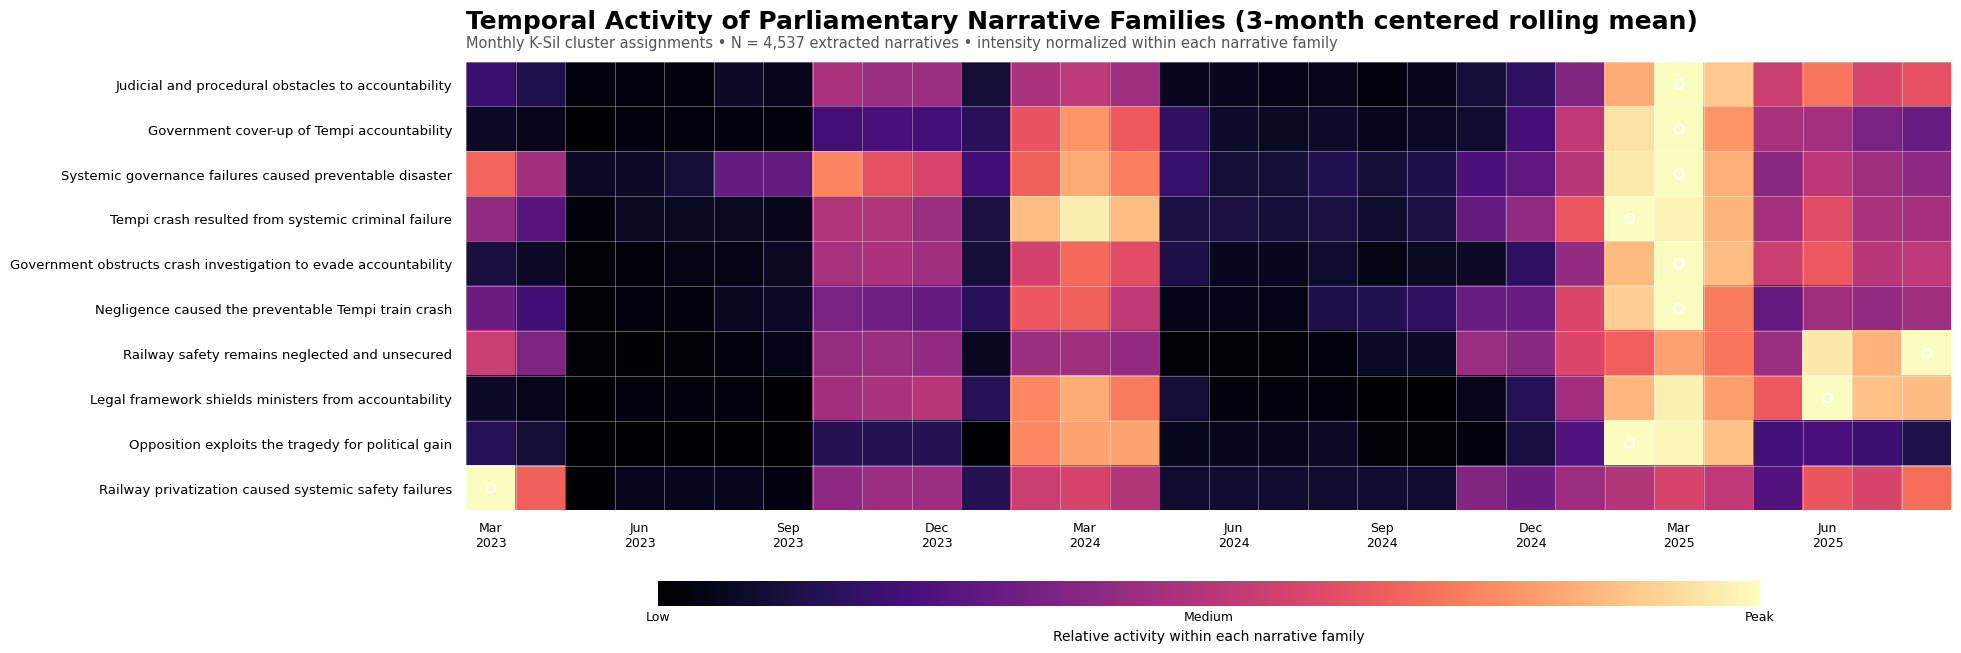

Date column used: sitting_date
Period: 2023-03 to 2025-08
Saved PDF: /content/cart/narrative_clusters_heatmap.pdf
Saved PNG: /content/cart/narrative_clusters_heatmap.png


In [31]:
# ============================================================
# Temporal evolution of the final K-Sil narrative clusters
# Publication-style narrative activity heatmap
# Requires: new_df and cluster_label_map from the cells above
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ---------- Settings ----------
FREQ = "MS"
ROLLING_MONTHS = 3
OUTPUT_STEM = "narrative_clusters_heatmap"
FIGSIZE = (22, 8.5)
DPI = 350

# Use row-wise normalization to emphasize temporal evolution
# within each narrative family.
NORMALIZE_BY_CLUSTER = True

# ---------- Validation ----------
if "new_df" not in globals():
    raise NameError(
        "Run the K-Sil clustering cell first so that `new_df` exists."
    )

plot_df = new_df.copy()

date_candidates = [
    "sitting_date",
    "Sitting_Date",
    "date",
    "Date",
    "speech_date",
    "session_date",
    "month",
    "Month"
]

date_col = next(
    (column for column in date_candidates if column in plot_df.columns),
    None
)

if date_col is None:
    fuzzy_candidates = [
        column
        for column in plot_df.columns
        if any(
            token in column.lower()
            for token in ("date", "month", "sitting")
        )
    ]

    if len(fuzzy_candidates) == 1:
        date_col = fuzzy_candidates[0]
    else:
        raise KeyError(
            "Could not identify the date column.\n"
            "Available columns:\n"
            + ", ".join(map(str, plot_df.columns))
        )

if "narratives_label" not in plot_df.columns:
    raise KeyError(
        "The column `narratives_label` is missing from `new_df`."
    )

# ---------- Date preparation ----------
plot_df["_date"] = pd.to_datetime(
    plot_df[date_col],
    errors="coerce",
    dayfirst=True
)

if plot_df["_date"].isna().all():
    plot_df["_date"] = pd.to_datetime(
        plot_df[date_col].astype(str).str.strip(),
        errors="coerce"
    )

invalid_dates = int(plot_df["_date"].isna().sum())

plot_df = plot_df.dropna(
    subset=["_date", "narratives_label"]
).copy()

plot_df["narratives_label"] = (
    plot_df["narratives_label"].astype(int)
)

if plot_df.empty:
    raise ValueError(
        f"No valid dated observations were found in `{date_col}`."
    )

# ---------- Monthly cluster counts ----------
monthly = (
    plot_df
    .groupby(
        [
            pd.Grouper(key="_date", freq=FREQ),
            "narratives_label"
        ]
    )
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

full_months = pd.date_range(
    monthly.index.min(),
    monthly.index.max(),
    freq=FREQ
)

monthly = monthly.reindex(
    full_months,
    fill_value=0
)

cluster_ids = sorted(
    monthly.columns.astype(int).tolist()
)

monthly = monthly.reindex(
    columns=cluster_ids,
    fill_value=0
)

# ---------- Optional smoothing ----------
if ROLLING_MONTHS > 1:
    monthly_plot = monthly.rolling(
        window=ROLLING_MONTHS,
        center=True,
        min_periods=1
    ).mean()
else:
    monthly_plot = monthly.astype(float)

# ---------- Cluster labels ----------
label_map = globals().get(
    "cluster_label_map",
    {
        cluster_id: f"Cluster {cluster_id}"
        for cluster_id in cluster_ids
    }
)

full_labels = [
    label_map.get(cluster_id, f"Cluster {cluster_id}")
    for cluster_id in cluster_ids
]

# Matrix shape: clusters × months
heatmap_values = monthly_plot.T.copy()

if NORMALIZE_BY_CLUSTER:
    row_maxima = heatmap_values.max(axis=1).replace(0, 1)

    heatmap_display = heatmap_values.div(
        row_maxima,
        axis=0
    )

    colorbar_label = (
        "Relative activity within each narrative family"
    )
else:
    heatmap_display = heatmap_values.copy()
    colorbar_label = "Narrative statements"

# ---------- Figure ----------
fig, ax = plt.subplots(figsize=FIGSIZE)

image = ax.imshow(
    heatmap_display.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap="magma",
    origin="upper"
)

# ---------- Y axis ----------
ax.set_yticks(
    np.arange(len(cluster_ids))
)

ax.set_yticklabels(
    full_labels,
    fontsize=9.5
)

ax.tick_params(
    axis="y",
    length=0,
    pad=10
)

# ---------- X axis ----------
month_positions = np.arange(
    len(monthly_plot.index)
)

tick_positions = month_positions[::3]

tick_labels = [
    date.strftime("%b\n%Y")
    for date in monthly_plot.index[::3]
]

ax.set_xticks(tick_positions)

ax.set_xticklabels(
    tick_labels,
    fontsize=9
)

ax.tick_params(
    axis="x",
    length=0,
    pad=8
)

# ---------- Cell separators ----------
ax.set_xticks(
    np.arange(-0.5, len(monthly_plot.index), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(cluster_ids), 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=0.7,
    alpha=0.35
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# ---------- Peak markers ----------
for row_index, cluster_id in enumerate(cluster_ids):

    values = monthly_plot[cluster_id]

    if values.max() <= 0:
        continue

    peak_position = int(
        np.argmax(values.to_numpy())
    )

    ax.scatter(
        peak_position,
        row_index,
        s=45,
        facecolors="none",
        edgecolors="white",
        linewidth=1.4,
        zorder=4
    )

# ---------- Axes styling ----------
ax.set_xlabel("")
ax.set_ylabel("")

for spine in (
    "top",
    "right",
    "left",
    "bottom"
):
    ax.spines[spine].set_visible(False)

# ---------- Title ----------
title_suffix = (
    f" ({ROLLING_MONTHS}-month centered rolling mean)"
    if ROLLING_MONTHS > 1
    else ""
)

ax.set_title(
    "Temporal Activity of Parliamentary Narrative Families"
    + title_suffix,
    loc="left",
    fontsize=18,
    fontweight="bold",
    pad=24
)

subtitle = (
    f"Monthly K-Sil cluster assignments • "
    f"N = {len(plot_df):,} extracted narratives"
)

if NORMALIZE_BY_CLUSTER:
    subtitle += (
        " • intensity normalized within each narrative family"
    )

if invalid_dates:
    subtitle += (
        f" • {invalid_dates:,} rows without a valid date omitted"
    )

ax.text(
    0,
    1.025,
    subtitle,
    transform=ax.transAxes,
    fontsize=10.5,
    color="#555555",
    va="bottom"
)

# ---------- Colorbar ----------
colorbar = fig.colorbar(
    image,
    ax=ax,
    orientation="horizontal",
    fraction=0.045,
    pad=0.13,
    aspect=45
)

colorbar.set_label(
    colorbar_label,
    fontsize=10
)

colorbar.ax.tick_params(
    labelsize=9,
    length=0
)

if NORMALIZE_BY_CLUSTER:
    colorbar.set_ticks(
        [0, 0.25, 0.50, 0.75, 1.0]
    )

    colorbar.set_ticklabels(
        ["Low", "", "Medium", "", "Peak"]
    )

colorbar.outline.set_visible(False)

fig.subplots_adjust(
    left=0.31,
    right=0.985,
    top=0.86,
    bottom=0.22
)

# ---------- Export ----------
output_dir = Path.cwd()

pdf_path = output_dir / f"{OUTPUT_STEM}.pdf"
png_path = output_dir / f"{OUTPUT_STEM}.png"

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

fig.savefig(
    png_path,
    dpi=DPI,
    bbox_inches="tight"
)

plt.show()

print(f"Date column used: {date_col}")
print(
    f"Period: {monthly.index.min():%Y-%m} "
    f"to {monthly.index.max():%Y-%m}"
)
print(f"Saved PDF: {pdf_path}")
print(f"Saved PNG: {png_path}")

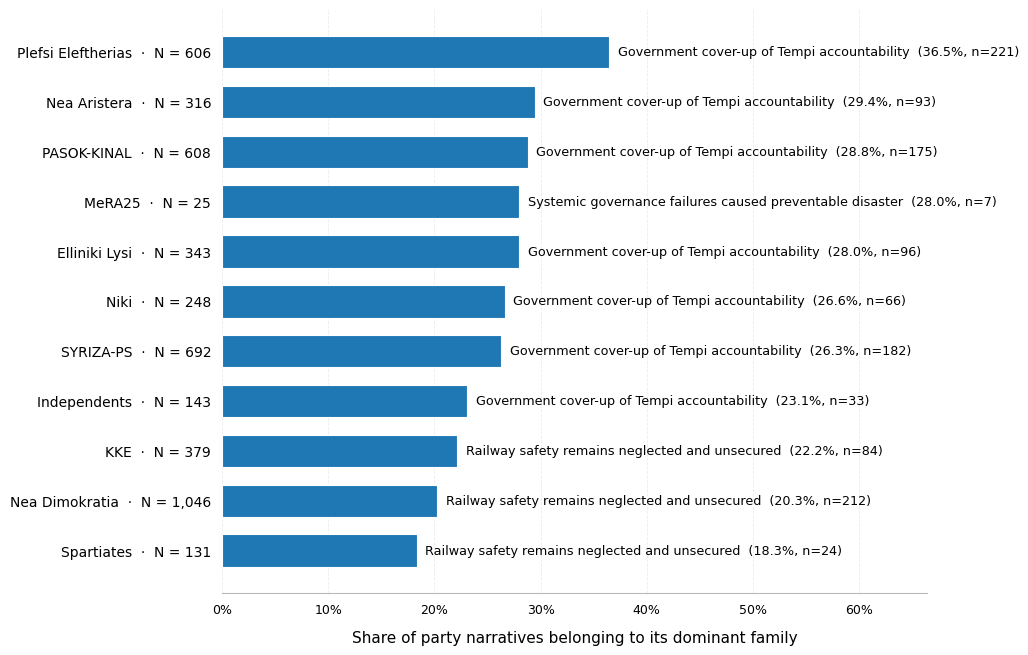

,party,party_n,...,top_count,top_share
0,Plefsi Eleftherias,606,...,221,36.5
1,Nea Aristera,316,...,93,29.4
2,PASOK-KINAL,608,...,175,28.8
3,MeRA25,25,...,7,28.0
4,Elliniki Lysi,343,...,96,28.0
5,Niki,248,...,66,26.6
6,SYRIZA-PS,692,...,182,26.3
7,Independents,143,...,33,23.1
8,KKE,379,...,84,22.2
9,Nea Dimokratia,1046,...,212,20.3


Saved PDF: /content/cart/top_narrative_by_party.pdf
Saved PNG: /content/cart/top_narrative_by_party.png


In [32]:
# ============================================================
# Top-1 narrative family by parliamentary party
# Publication-ready horizontal bar chart
#
# Each bar = one party
# Bar length = share of the party's most frequent narrative
# Bar label = dominant narrative family
#
# Requires:
#   - new_df
#   - cluster_label_map
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# Settings
# ============================================================

PARTY_COL = "party"
CLUSTER_COL = "narratives_label"

OUTPUT_STEM = "top_narrative_by_party"
FIGSIZE = (15, 8)
DPI = 350

# Minimum number of extracted narratives required
# for a party to appear in the figure
MIN_PARTY_N = 1

# Set to an integer to keep only the largest parties
# Example: MAX_PARTIES = 10
# Use None to include all parties
MAX_PARTIES = None

# Sort parties by:
#   "share"  = strongest top narrative first
#   "count"  = largest parties first
SORT_BY = "share"


# ============================================================
# Validation
# ============================================================

if "new_df" not in globals():
    raise NameError(
        "Run the clustering cell first so that `new_df` exists."
    )

plot_df = new_df.copy()

required_columns = [
    PARTY_COL,
    CLUSTER_COL
]

missing_columns = [
    column
    for column in required_columns
    if column not in plot_df.columns
]

if missing_columns:
    raise KeyError(
        "Missing required columns: "
        + ", ".join(missing_columns)
    )


# ============================================================
# Data preparation
# ============================================================

plot_df[PARTY_COL] = (
    plot_df[PARTY_COL]
    .astype("string")
    .str.strip()
)

plot_df[CLUSTER_COL] = pd.to_numeric(
    plot_df[CLUSTER_COL],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=[
        PARTY_COL,
        CLUSTER_COL
    ]
).copy()

plot_df = plot_df[
    plot_df[PARTY_COL].ne("")
].copy()

plot_df[CLUSTER_COL] = (
    plot_df[CLUSTER_COL]
    .astype(int)
)

if plot_df.empty:
    raise ValueError(
        "No valid party and narrative observations were found."
    )


# ============================================================
# Party selection
# ============================================================

party_counts = (
    plot_df[PARTY_COL]
    .value_counts()
)

party_counts = party_counts[
    party_counts >= MIN_PARTY_N
]

if MAX_PARTIES is not None:
    party_counts = party_counts.head(
        MAX_PARTIES
    )

parties = party_counts.index.tolist()

plot_df = plot_df[
    plot_df[PARTY_COL].isin(parties)
].copy()

if not parties:
    raise ValueError(
        "No parties satisfy the selected threshold."
    )


# ============================================================
# Party × narrative counts
# ============================================================

counts = pd.crosstab(
    plot_df[PARTY_COL],
    plot_df[CLUSTER_COL]
)

counts = counts.reindex(
    index=parties,
    fill_value=0
)

party_totals = counts.sum(
    axis=1
)

top_cluster = counts.idxmax(
    axis=1
)

top_count = counts.max(
    axis=1
)

top_share = (
    top_count
    .div(party_totals)
    .mul(100)
)


# ============================================================
# Narrative labels
# ============================================================

label_map = globals().get(
    "cluster_label_map",
    {
        cluster_id: f"Cluster {cluster_id}"
        for cluster_id in counts.columns
    }
)

top_labels = top_cluster.map(
    lambda cluster_id: label_map.get(
        int(cluster_id),
        f"Cluster {int(cluster_id)}"
    )
)


# ============================================================
# Final plotting dataframe
# ============================================================

result = pd.DataFrame({
    "party": parties,
    "party_n": [
        int(party_totals.loc[party])
        for party in parties
    ],
    "top_cluster": [
        int(top_cluster.loc[party])
        for party in parties
    ],
    "top_narrative": [
        top_labels.loc[party]
        for party in parties
    ],
    "top_count": [
        int(top_count.loc[party])
        for party in parties
    ],
    "top_share": [
        float(top_share.loc[party])
        for party in parties
    ]
})


# ============================================================
# Sorting
# ============================================================

if SORT_BY == "share":

    result = result.sort_values(
        by=[
            "top_share",
            "party_n"
        ],
        ascending=[
            False,
            False
        ]
    )

elif SORT_BY == "count":

    result = result.sort_values(
        by="party_n",
        ascending=False
    )

else:

    raise ValueError(
        "SORT_BY must be either 'share' or 'count'."
    )

result = result.reset_index(
    drop=True
)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=FIGSIZE
)

y_positions = np.arange(
    len(result)
)

bars = ax.barh(
    y_positions,
    result["top_share"],
    height=0.65,
    edgecolor="white",
    linewidth=0.8
)


# ============================================================
# Y-axis party labels
# ============================================================

party_labels = [
    f"{row.party}  ·  N = {row.party_n:,}"
    for row in result.itertuples()
]

ax.set_yticks(
    y_positions
)

ax.set_yticklabels(
    party_labels,
    fontsize=10
)

ax.invert_yaxis()


# ============================================================
# Labels at the end of each bar
# ============================================================

for bar, row in zip(
    bars,
    result.itertuples()
):

    bar_width = bar.get_width()
    y_center = (
        bar.get_y()
        + bar.get_height() / 2
    )

    ax.text(
        bar_width + 0.8,
        y_center,
        (
            f"{row.top_narrative}  "
            f"({row.top_share:.1f}%, n={row.top_count:,})"
        ),
        va="center",
        ha="left",
        fontsize=9.2
    )


# ============================================================
# Axes
# ============================================================

maximum_share = result["top_share"].max()

ax.set_xlim(
    0,
    min(
        100,
        maximum_share + 30
    )
)

ax.set_xlabel(
    "Share of party narratives belonging to its dominant family",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

ax.xaxis.set_major_formatter(
    lambda value, position: f"{value:.0f}%"
)

ax.tick_params(
    axis="x",
    labelsize=9,
    length=0,
    pad=7
)

ax.tick_params(
    axis="y",
    length=0,
    pad=8
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.24
)

ax.set_axisbelow(
    True
)

for spine in (
    "top",
    "right",
    "left"
):
    ax.spines[spine].set_visible(
        False
    )

ax.spines["bottom"].set_color(
    "#B8B8B8"
)


# ============================================================
# Title and subtitle
# ============================================================

ax.set_title(
    "",
    loc="left",
    fontsize=18,
    fontweight="bold",
    pad=22
)


# ============================================================
# Layout and export
# ============================================================

fig.subplots_adjust(
    left=0.25,
    right=0.72,
    top=0.87,
    bottom=0.14
)

output_dir = Path.cwd()

pdf_path = (
    output_dir
    / f"{OUTPUT_STEM}.pdf"
)

png_path = (
    output_dir
    / f"{OUTPUT_STEM}.png"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

fig.savefig(
    png_path,
    dpi=DPI,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Results table
# ============================================================

display(
    result[
        [
            "party",
            "party_n",
            "top_narrative",
            "top_count",
            "top_share"
        ]
    ].round({
        "top_share": 1
    })
)

print(f"Saved PDF: {pdf_path}")
print(f"Saved PNG: {png_path}")

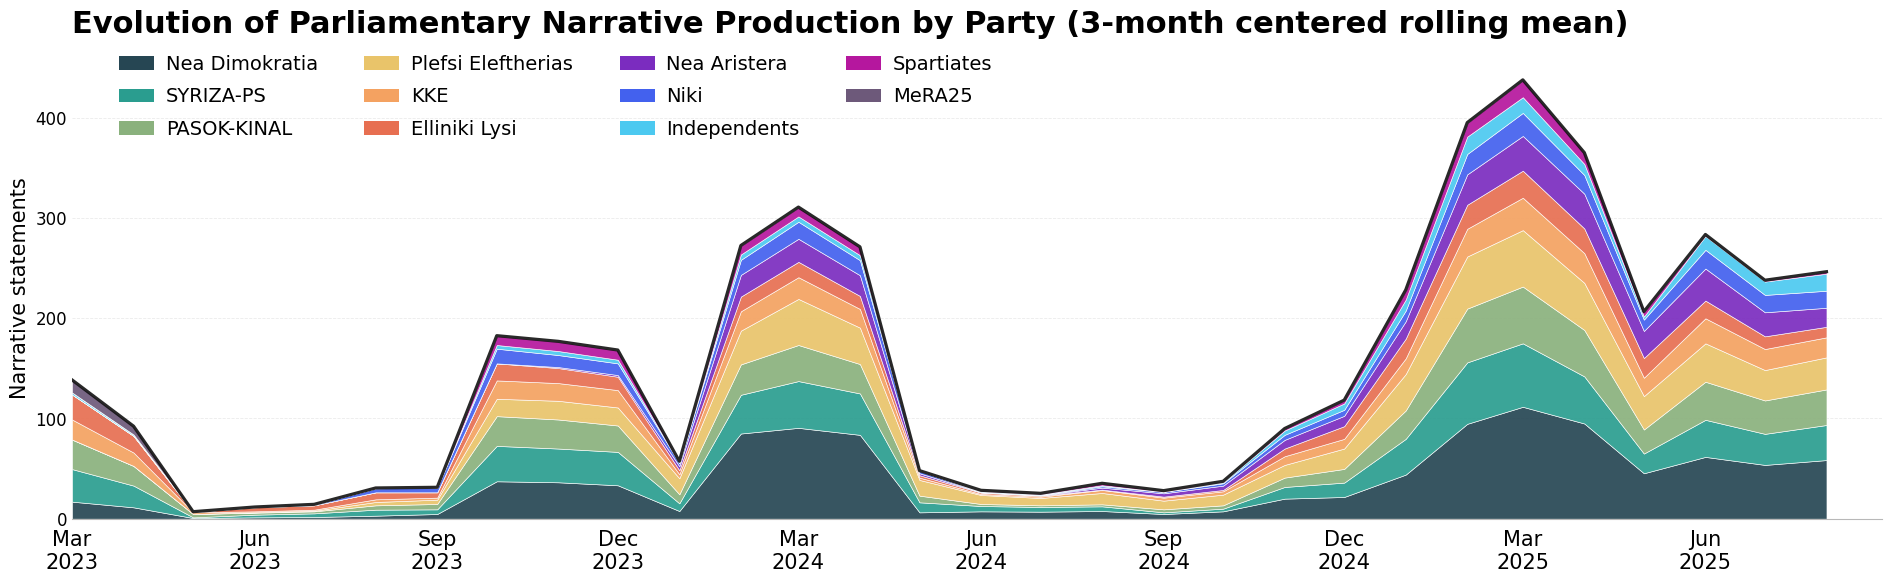

Date column used: sitting_date
Party column used: party
Period: 2023-03 to 2025-08
Parties included: 11

Narrative statements by party:
  Nea Dimokratia: 1,046
  SYRIZA-PS: 692
  PASOK-KINAL: 608
  Plefsi Eleftherias: 606
  KKE: 379
  Elliniki Lysi: 343
  Nea Aristera: 316
  Niki: 248
  Independents: 143
  Spartiates: 131
  MeRA25: 25

Saved PDF: /content/cart/narrative_statements_over_time_by_party.pdf
Saved PNG: /content/cart/narrative_statements_over_time_by_party.png


In [33]:
# ============================================================
# Temporal evolution of narrative production by party
# Publication-ready wide stacked time series
#
# One chart only:
#   x-axis  = month
#   y-axis  = number of narrative statements
#   colors  = parliamentary parties
#
# Requires: new_df
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from pathlib import Path

# ---------- Settings ----------
DATE_COL = "sitting_date"
PARTY_COL = "party"

FREQ = "MS"                 # monthly aggregation
ROLLING_MONTHS = 3          # 1 = raw counts; use 2 or 3 for smoothing
OUTPUT_STEM = "narrative_statements_over_time_by_party"
FIGSIZE = (20, 7.2)
DPI = 600

# Minimum number of narrative statements required for a party
# to appear in the figure.
MIN_PARTY_N = 1

# Set to an integer to keep only the largest parties.
# Example: MAX_PARTIES = 8
# Use None to include all parties.
MAX_PARTIES = None

# Optional manual ordering.
# Leave as None to order parties by total narrative volume.
PARTY_ORDER = None

# Example:
# PARTY_ORDER = [
#     "New Democracy",
#     "SYRIZA",
#     "PASOK-KINAL",
#     "KKE",
#     "Greek Solution"
# ]

# ---------- Validation ----------
if "new_df" not in globals():
    raise NameError(
        "Run the K-Sil clustering cell first so that `new_df` exists."
    )

plot_df = new_df.copy()

required_columns = [
    DATE_COL,
    PARTY_COL
]

missing_columns = [
    column
    for column in required_columns
    if column not in plot_df.columns
]

if missing_columns:
    raise KeyError(
        "The following required columns are missing from `new_df`: "
        + ", ".join(missing_columns)
    )

# ---------- Date and party preparation ----------
plot_df["_date"] = pd.to_datetime(
    plot_df[DATE_COL],
    errors="coerce",
    dayfirst=True
)

# Second attempt for dates stored in unusual string formats
if plot_df["_date"].isna().all():
    plot_df["_date"] = pd.to_datetime(
        plot_df[DATE_COL].astype(str).str.strip(),
        errors="coerce"
    )

invalid_dates = int(
    plot_df["_date"].isna().sum()
)

plot_df[PARTY_COL] = (
    plot_df[PARTY_COL]
    .astype("string")
    .str.strip()
)

plot_df = plot_df.dropna(
    subset=[
        "_date",
        PARTY_COL
    ]
).copy()

plot_df = plot_df[
    plot_df[PARTY_COL].ne("")
].copy()

if plot_df.empty:
    raise ValueError(
        "No valid observations remain after date and party preparation."
    )

# ---------- Party selection and ordering ----------
party_counts = (
    plot_df[PARTY_COL]
    .value_counts()
)

party_counts = party_counts[
    party_counts >= MIN_PARTY_N
]

if MAX_PARTIES is not None:
    party_counts = party_counts.head(
        MAX_PARTIES
    )

selected_parties = party_counts.index.tolist()

if PARTY_ORDER is not None:
    ordered_parties = [
        party
        for party in PARTY_ORDER
        if party in selected_parties
    ]

    remaining_parties = [
        party
        for party in selected_parties
        if party not in ordered_parties
    ]

    parties = (
        ordered_parties
        + remaining_parties
    )
else:
    # Largest parties are placed at the bottom of the stack.
    parties = selected_parties

if not parties:
    raise ValueError(
        "No parties satisfy the selected frequency threshold."
    )

plot_df = plot_df[
    plot_df[PARTY_COL].isin(parties)
].copy()

# ---------- Monthly party counts ----------
monthly = (
    plot_df
    .groupby([
        pd.Grouper(
            key="_date",
            freq=FREQ
        ),
        PARTY_COL
    ])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Include months with zero narrative instances
full_months = pd.date_range(
    monthly.index.min().to_period("M").to_timestamp(),
    monthly.index.max().to_period("M").to_timestamp(),
    freq=FREQ
)

monthly = monthly.reindex(
    index=full_months,
    fill_value=0
)

monthly = monthly.reindex(
    columns=parties,
    fill_value=0
)

# ---------- Optional smoothing ----------
if ROLLING_MONTHS > 1:
    monthly_plot = monthly.rolling(
        window=ROLLING_MONTHS,
        center=True,
        min_periods=1
    ).mean()
else:
    monthly_plot = monthly.astype(float)

# ---------- Colors ----------
base_colors = [
    "#264653",
    "#2A9D8F",
    "#8AB17D",
    "#E9C46A",
    "#F4A261",
    "#E76F51",
    "#7B2CBF",
    "#4361EE",
    "#4CC9F0",
    "#B5179E",
    "#6D597A",
    "#355070",
    "#EAAC8B",
    "#84A98C",
    "#52796F"
]

if len(parties) <= len(base_colors):
    colors = base_colors[:len(parties)]
else:
    color_map = plt.get_cmap("tab20")

    colors = [
        color_map(
            index / max(len(parties) - 1, 1)
        )
        for index in range(len(parties))
    ]

# ---------- Visual design ----------
fig, ax = plt.subplots(
    figsize=FIGSIZE
)

ax.stackplot(
    monthly_plot.index,
    *[
        monthly_plot[party].to_numpy()
        for party in parties
    ],
    colors=colors,
    alpha=0.92,
    linewidth=0.45,
    edgecolor="white"
)

# Black upper envelope showing total monthly narrative volume
monthly_total = monthly_plot.sum(axis=1)

ax.plot(
    monthly_plot.index,
    monthly_total,
    color="#111111",
    linewidth=2.3,
    alpha=0.9,
    zorder=5
)

# ---------- Axes ----------
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b\n%Y")
)

ax.tick_params(
    axis="x",
    labelsize=15,
    length=0,
    pad=8
)

ax.tick_params(
    axis="y",
    labelsize=12,
    length=0
)

ax.set_ylabel(
    "Narrative statements",
    fontsize=15
)

ax.set_xlabel("")

ax.set_xlim(
    monthly_plot.index.min(),
    monthly_plot.index.max() + pd.DateOffset(days=28)
)

ax.set_ylim(bottom=0)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#B8B8B8")

# ---------- Title ----------
title_suffix = (
    f" ({ROLLING_MONTHS}-month centered rolling mean)"
    if ROLLING_MONTHS > 1
    else ""
)

ax.set_title(
    "Evolution of Parliamentary Narrative Production by Party"
    + title_suffix,
    loc="left",
    fontsize=22,
    fontweight="bold",
    pad=18
)

# ---------- Legend ----------
legend_handles = [
    Patch(
        facecolor=color,
        edgecolor="none",
        label=party
    )
    for color, party in zip(
        colors,
        parties
    )
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.012, 1.062),
    ncol=4,
    frameon=False,
    fancybox=False,
    framealpha=0.95,
    fontsize=14,
    handlelength=1.8,
    handletextpad=0.6,
    columnspacing=2.4,
    labelspacing=0.7,
    borderpad=0.8
)

fig.subplots_adjust(
    left=0.08,
    right=0.985,
    top=0.90,
    bottom=0.26
)

# ---------- Export ----------
output_dir = Path.cwd()

pdf_path = (
    output_dir
    / f"{OUTPUT_STEM}.pdf"
)

png_path = (
    output_dir
    / f"{OUTPUT_STEM}.png"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

fig.savefig(
    png_path,
    dpi=DPI,
    bbox_inches="tight"
)

plt.show()

# ---------- Summary ----------
print(
    f"Date column used: {DATE_COL}"
)

print(
    f"Party column used: {PARTY_COL}"
)

print(
    f"Period: {monthly.index.min():%Y-%m} "
    f"to {monthly.index.max():%Y-%m}"
)

print(
    f"Parties included: {len(parties)}"
)

if invalid_dates:
    print(
        f"Rows without a valid date omitted: {invalid_dates:,}"
    )

print(
    "\nNarrative statements by party:"
)

for party in parties:
    print(
        f"  {party}: "
        f"{int(party_counts.loc[party]):,}"
    )

print(
    f"\nSaved PDF: {pdf_path}"
)

print(
    f"Saved PNG: {png_path}"
)

### Export Final Narrative Taxonomy

In [34]:
from google.colab import files

taxonomy = new_df[["narrative", "narratives_label", "narrative_label_clean"]].copy()

display(taxonomy.head(10))

taxonomy.to_csv("narrative_taxonomy_ksil.csv", index=False)

files.download("narrative_taxonomy_ksil.csv")

,narrative,narratives_label,narrative_label_clean
0,Systemic political neglect necessitates railway modernization and accountability.,6,Railway safety remains neglected and unsecured
1,Government negligence in railway signaling caused preventable crash.,6,Railway safety remains neglected and unsecured
2,Successive governments neglected infrastructure and staffing causing preventable disaster.,2,Systemic governance failures caused preventable disaster
3,Government must immediately implement specific railway safety measures.,6,Railway safety remains neglected and unsecured
4,Government responsible for criminal negligence in crash,4,Government obstructs crash investigation to evade accountability
5,The Tempi train crash was a political crime.,5,Negligence caused the preventable Tempi train crash
6,Successive governments caused systemic safety failures through prolonged neglect.,2,Systemic governance failures caused preventable disaster
7,Government neglected railway safety despite prior warnings.,6,Railway safety remains neglected and unsecured
8,Government ignored known rail safety deficiencies endangering passengers,6,Railway safety remains neglected and unsecured
9,Systemic political negligence caused preventable railway safety failures.,6,Railway safety remains neglected and unsecured


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>